In [2]:
import os, sys, pathlib

import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent          # analysis/ -> FitNMF/
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


import pandas as pd 
import numpy as np
from scipy.stats import betabinom, nbinom
from scipy.spatial.distance import cdist
from src.model import joint_soft_dynamics_nmf
from src.helpers import binarize_signature_matrix, _parse_dates
from evaluation.plot_joint_matched_heatmap import plot_matched_heatmap_and_abundances
from src.nmf_update_fitness import compute_p

import matplotlib.patheffects as pe
from venn import venn
import json
import matplotlib.pyplot as plt
import seaborn as sns
import re
from matplotlib.gridspec import GridSpec
import matplotlib.dates as mdates
from joblib import Parallel, delayed, parallel_backend
from scipy.optimize import linear_sum_assignment
import matplotlib as mpl
from scipy.spatial.distance import cdist


In [3]:
def _match_components_to_ground_truth(W_binary, W_covspectrum,
                                        unassigned_threshold=0.5,
                                        unassigned_label='unassigned'):
    """
    Strict one-to-one matching via the Hungarian algorithm: each component
    is paired with at most one ground-truth variant and vice versa,
    maximizing the TOTAL summed Jaccard similarity across all pairs
    simultaneously -- unlike per-component argmax, this won't let two
    components both claim the same variant while a third gets none.
    NOTE! This is different from the real data predictions evalutation, where multiple components can be matched to the same variant.

    Handles rank != n_variants: linear_sum_assignment naturally produces
    only min(rank, n_variants) pairs; anything left over is genuinely
    unmatched, not just thresholded away.
    """
    all_muts = sorted(set(W_binary.index) | set(W_covspectrum.index))
    W_pred_final = W_binary.reindex(all_muts, fill_value=0)
    W_true_final = W_covspectrum.reindex(all_muts, fill_value=0)

    dist_matrix = cdist(W_pred_final.values.T, W_true_final.values.T, metric='jaccard')
    sim_matrix = 1 - dist_matrix
    sim_df = pd.DataFrame(sim_matrix, index=W_binary.columns, columns=W_covspectrum.columns)
    sim_df = sim_df.fillna(0.0)

    row_ind, col_ind = linear_sum_assignment(-sim_df.values)  # negate to maximize total similarity

    best_labels = [unassigned_label] * sim_df.shape[0]
    for i, j in zip(row_ind, col_ind):
        sim = sim_df.values[i, j]
        best_labels[i] = sim_df.columns[j] if sim >= unassigned_threshold else unassigned_label

    counts = {}
    new_labels = []
    for lbl in best_labels:
        counts[lbl] = counts.get(lbl, 0) + 1
        new_labels.append(lbl if counts[lbl] == 1 else f"{lbl} ({counts[lbl]})")

    return sim_df, new_labels, best_labels

In [4]:
def _fitness_per_variant_from_result(result, df, W_covspectrum, all_vars,
                                      binarize_threshold, unassigned_threshold):
    """Matches NMF components to ground-truth variants (same pipeline as the
    Jaccard matching) and returns {variant: fitness estimate} using result.f."""
    rank = result.W.shape[1]
    W_df = pd.DataFrame(result.W, index=list(df.index),
                         columns=[f'Component_{k}' for k in range(rank)])
    W_binary = (W_df >= binarize_threshold).astype(int)

    sim_df, new_labels, best_labels = _match_components_to_ground_truth(
        W_binary, W_covspectrum, unassigned_threshold=unassigned_threshold)
    sim_df.index = new_labels
    label_to_k = {label: k for k, label in enumerate(new_labels)}

    gt_to_pred_labels = {}
    for pred_label, gt_label in zip(new_labels, best_labels):
        gt_to_pred_labels.setdefault(gt_label, []).append(pred_label)

    fitness_per_variant = {}
    for v in all_vars:
        candidates = gt_to_pred_labels.get(v, [])
        if not candidates:
            fitness_per_variant[v] = np.nan
            continue
        scores = {pl: sim_df.loc[pl, v] for pl in candidates}
        best_pl = max(scores, key=scores.get)
        fitness_per_variant[v] = result.f[label_to_k[best_pl]]
    return fitness_per_variant

In [5]:
W_covspectrum = pd.read_csv('../resources/variants_definitions_sars/variant_signatures_covspectrum_2026_08_27.csv',
                                       header=0, index_col=0)


# Estimate mean coverage depth per signature mutation 

In [6]:
signatures_depth = pd.read_csv("../data/signature_coverage/datamatrix_coverage_signature_ZH.csv", index_col=0)
frac_missing_or_low = (signatures_depth.isna() | (signatures_depth < 30)).values.mean()

print(f"NaN or <30x: {frac_missing_or_low:.1%}")

mean_coverage_depth = round(np.nanmean(signatures_depth.to_numpy()),ndigits=0)
sigma2_hat = round(np.nanvar(signatures_depth.to_numpy(), ddof=1),ndigits=0)
print(mean_coverage_depth, sigma2_hat)

mean_coverage_depth = 67e+03
sigma2_hat = 2.5e+10


mu_hat, sigma2_hat = mean_coverage_depth, sigma2_hat  # your estimated values
r = mu_hat**2 / (sigma2_hat - mu_hat)
p = mu_hat / sigma2_hat

sim = nbinom.rvs(r, p, size=1_000_000)
print("target mean:", mu_hat, " simulated mean:", sim.mean())
print("target var: ", sigma2_hat, " simulated var:", sim.var())

print("r: ", r)
print("p: ", p)

NaN or <30x: 18.5%
66541.0 25475262615.0
target mean: 67000.0  simulated mean: 67109.952292
target var:  25000000000.0  simulated var: 24972036559.73996
r:  0.17956048122208967
p:  2.68e-06


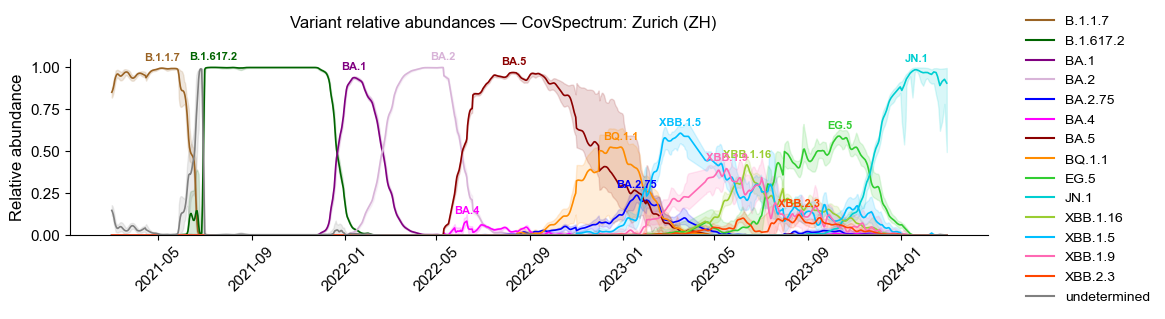

In [7]:
# True relative abundances obtained by Lollipop

with open("../data/public_wastewater_data_share/ww_update_data_combined.json", 'r') as f:
    data = json.load(f)

# ── Parse ─────────────────────────────────────────────────────────────────────
rows = []
for loc, variants_dict in data.items():
    for variant, inner in variants_dict.items():

        # handle both list and dict with timeseriesSummary
        if isinstance(inner, list):
            records = inner
        elif isinstance(inner, dict) and 'timeseriesSummary' in inner:
            records = inner['timeseriesSummary']
        else:
            records = list(inner.values())[0] if inner else []

        for rec in records:
            rows.append({
                'location':        loc,
                'variant':         variant,
                'date':            pd.to_datetime(rec['date']),
                'proportion':      rec.get('proportion',      np.nan),
                'proportionLower': rec.get('proportionLower', np.nan),
                'proportionUpper': rec.get('proportionUpper', np.nan)
            })

df = pd.DataFrame(rows).sort_values(['location', 'variant', 'date'])
# ── Filter date range ─────────────────────────────────────────────────────────
df = df[
    (df['date'] >= '2021-03-01') &
    (df['date'] <= '2024-03-01')]
# Filter the location
df = df[df['location'] == 'Zürich (ZH)']

# print(f"Locations: {df['location'].unique()}")
# print(f"Variants:  {df['variant'].unique()}")
# print(f"Shape:     {df.shape}")

# ── Plot ──────────────────────────────────────────────────────────────────────

locations = sorted(df['location'].unique())

# ── CovSpectrum-style colors ──────────────────────────────────────────────────
covspectrum_colors = {
    'undetermined': '#808080',
    'B.1.1.7':   '#9a6324',  # grey
    'B.1.351':   '#ff0000',  # red
    'P.1':       '#00ff00',  # bright green
    'B.1.617.2': '#006400',  # dark green
    'BA.1':      '#800080',  # purple
    'BA.2':      '#d8b4d8',  # light purple/lavender
    'BA.2.75':   '#0000ff',  # blue
    'BA.4':      '#ff00ff',  # magenta
    'BA.5':      '#8b0000',  # dark red/brown
    'BQ.1.1':    '#ff8c00',  # orange
    'XBB.1.5':   '#00bfff',  # light blue
    'XBB.1.9':   '#ff69b4',  # pink
    'XBB.1.16':  '#9acd32',  # yellow green
    'XBB.2.3':   '#ff4500',  # red orange
    'EG.5':      '#32cd32',  # lime green
    'BA.2.86':   '#8b4513',  # brown
    'JN.1':      '#00ced1',  # dark turquoise
    'KP.2':      '#4169e1',  # royal blue
    'KP.3':      '#9400d3',  # dark violet
}

# ── Fallback for variants not in dict ────────────────────────────────────────
fallback_colors = [
    '#e6194b', '#3cb44b', '#4363d8', '#f58231', '#911eb4',
    '#42d4f4', '#f032e6', '#bfef45', '#469990', '#9a6324',
]

def get_color(variant, idx):
    if variant in covspectrum_colors:
        return covspectrum_colors[variant]
    return fallback_colors[idx % len(fallback_colors)]

variants = sorted(df['variant'].unique())
colors   = {v: get_color(v, i) for i, v in enumerate(variants)}



fig, axes = plt.subplots(len(locations), 1,
                          figsize=(10, 3),
                          sharex=True)

if len(locations) == 1:
    axes = [axes]

# ── Filter variants that appeared above x % for at least y days ───────────────
def variant_appeared(df_v, threshold=0.05, min_days=10):
    return (df_v['proportion'] > threshold).sum() >= min_days

for ax, loc in zip(axes, locations):
    df_loc = df[df['location'] == loc]

    for variant in variants:
        df_v = df_loc[df_loc['variant'] == variant].sort_values('date')

        if df_v.empty:
            continue

        # ── Skip if never above x% for y+ days ───────────────────────────────
        if not variant_appeared(df_v):
            continue

        color = colors[variant]
        ax.plot(df_v['date'], df_v['proportion'],
                color=color, linewidth=1.2)

        if not df_v['proportionLower'].isna().all():
            ax.fill_between(df_v['date'],
                            df_v['proportionLower'],
                            df_v['proportionUpper'],
                            color=color, alpha=0.15)

        # ── Label at peak ─────────────────────────────────────────────────────
        peak_idx = df_v['proportion'].idxmax()
        peak_x   = df_v.loc[peak_idx, 'date']
        peak_y   = df_v.loc[peak_idx, 'proportion']

        if peak_y > 0.05 and variant != 'undetermined':
            ax.annotate(
                variant,
                xy=(peak_x, peak_y),
                xytext=(0, 4),
                textcoords='offset points',
                ha='center', va='bottom',
                fontsize=8,
                color=color,
                fontweight='bold')

    ax.set_ylabel('Relative abundance', fontsize=12)
    #ax.set_title('Zürich (ZH)', fontsize=15)
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis='x', rotation=45, labelsize=11)
    ax.tick_params(axis='y', labelsize=11)
    ax.spines[['top', 'right']].set_visible(False)



# ── Build legend only for variants that appeared in at least one location ─────
active_variants = []
for variant in variants:
    df_v = df[df['variant'] == variant]
    if variant_appeared(df_v):
        active_variants.append(variant)

# ── Legend — only active variants ────────────────────────────────────────────
handles = [plt.Line2D([0], [0], color=colors[v], linewidth=1.5, label=v)
           for v in active_variants]  


fig.legend(handles=handles,
           bbox_to_anchor=(1.01, 0.5),
           loc='center left',
           fontsize=10, frameon=False)


plt.suptitle('Variant relative abundances — CovSpectrum: Zurich (ZH)', fontsize=12)
plt.tight_layout()
plt.show()

# Simulate relative abundances

In [8]:
def fit_multi_variant_window(df, location, variants, ref_variant, date_start, date_end):
    sub = df[(df['location'] == location) &
             (df['date'] >= date_start) & (df['date'] <= date_end)]
    t0 = pd.to_datetime(date_start)   # shared origin across ALL variants
    ref = sub[sub['variant'] == ref_variant].set_index('date')['proportion'].sort_index()

    all_vars = [ref_variant] + list(variants)
    b = {ref_variant: 0.0}; f = {ref_variant: 0.0}
    eps = 1e-4

    for var in variants:
        v = sub[sub['variant'] == var].set_index('date')['proportion'].sort_index()
        joined = pd.concat([v.rename('p_v'), ref.rename('p_r')], axis=1).dropna()
        t = (joined.index - t0).days.astype(float)
        p_v = np.clip(joined['p_v'].values, eps, 1 - eps)
        p_r = np.clip(joined['p_r'].values, eps, 1 - eps)
        y = np.log(p_v) - np.log(p_r)
        A = np.vstack([np.ones_like(t), t]).T
        (b_i, f_i), *_ = np.linalg.lstsq(A, y, rcond=None)
        b[var], f[var] = b_i, f_i

    b_arr = np.array([b[v] for v in all_vars])
    f_arr = np.array([f[v] for v in all_vars])
    return b_arr, f_arr, all_vars, t0

def simulate_logistic_growth_multi(date_range, t0, b, f):
    """b, f: arrays of length K (index 0 = reference, b[0]=f[0]=0).
       Returns (len(date_range), K) simulated relative abundances."""
    t = (pd.DatetimeIndex(date_range) - t0).days.to_numpy().astype(float)
    b = np.asarray(b); f = np.asarray(f)
    logits = b[None, :] + f[None, :] * t[:, None]
    e = np.exp(logits)
    return e / e.sum(axis=1, keepdims=True)

# Simulate Alpha, Delta, BA.1 (sequential take-over)

[  0.          -5.36547548 -11.11948805] [0.         0.03378767 0.05572855] ['B.1.1.7', 'B.1.617.2', 'BA.1'] 2021-03-01 00:00:00


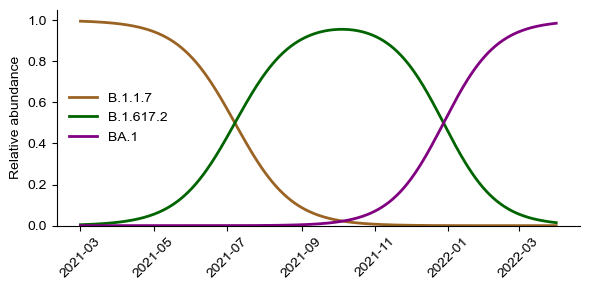

In [9]:
variants   = ['B.1.617.2', 'BA.1']
ref_variant = 'B.1.1.7'
date_start, date_end = '2021-03-01', '2022-04-01'

b_arr, f_arr, all_vars, t0 = fit_multi_variant_window(
    df, 'Zürich (ZH)', variants, ref_variant, date_start, date_end)
print(b_arr, f_arr, all_vars, t0)
b_arr = [ 0.0, -5.4, -19.0]
f_arr = [0.0, 0.042, 0.087]
date_range = pd.date_range(date_start, date_end)
P_sim = simulate_logistic_growth_multi(date_range, t0, b_arr, f_arr)

fig, ax = plt.subplots(figsize=(6, 3))
for i, var in enumerate(all_vars):
    obs = df[(df['location'] == 'Zürich (ZH)') & (df['variant'] == var) &
             (df['date'] >= date_start) & (df['date'] <= date_end)].set_index('date')['proportion']
    color = colors.get(var, f'C{i}')
    ax.plot(date_range, P_sim[:, i], color=color, linewidth=2, label=var)

ax.set_ylabel('Relative abundance'); ax.set_ylim(0, 1.05)
ax.spines[['top', 'right']].set_visible(False)
ax.tick_params(axis='x', rotation=45)
ax.legend(frameon=False, fontsize=10, ncol=1)
plt.tight_layout()
#plt.savefig('results/fitted_multi_variant_window.pdf', bbox_inches='tight')
plt.show()

In [10]:
X = W_covspectrum[all_vars].copy()
X = X.loc[X.sum(axis=1) > 0]          # drop mutations absent from all 3 variants

abundance_matrix = P_sim
dates = date_range
mutation_freq = X.values @ abundance_matrix.T

In [11]:
# ── Noise injection (varies by quality group) ────────────────────────────────────
def simulate_observed(mutation_freq, dates, index,
                       mu, sigma2_depth, gamma,
                       delta, missing_frac, seed=42):
    rng = np.random.default_rng(seed)
    y = (mutation_freq + delta) / (1 + 2 * delta)

    r = mu**2 / (sigma2_depth - mu)
    p = mu / sigma2_depth
    depth = nbinom.rvs(r, p, size=y.shape, random_state=rng)
    depth = np.maximum(depth, 1)

    y_observed = betabinom.rvs(depth, y * (1 - gamma)/gamma, (1 - y)*(1-gamma)/gamma,
                                random_state=rng) / depth
    y_observed_missing = y_observed.copy()
    y_observed_missing[rng.random(y_observed.shape) < missing_frac] = np.nan

    df = pd.DataFrame(y_observed_missing, index=index, columns=dates)
    depth_df = pd.DataFrame(depth, index=index, columns=dates)
    return df, depth_df


# ── Quality tiers: best -> worst ─────────────────────────────────────────────────
gammas = [0.001, 0.01, 0.1]
missing_fracs = [round(m / 10, 2) for m in range(10)] + [0.95]  # 0.0, 0.1, 0.2, ..., 0.9

QUALITY_TIERS = [
    dict(name=f'disp{d_idx+1}_missing_{m_idx+1}',
         mu=6.7e4, sigma2_depth=2.5e10, gamma=gamma, delta=0.0025, missing_frac=mf)
    for d_idx, gamma in enumerate(gammas)
    for m_idx, mf in enumerate(missing_fracs)
]


def build_quality_datasets(X, abundance_matrix, mutation_freq, dates,
                            seed=42, quality_tiers=QUALITY_TIERS):
    """
    Simulate one observed dataset per quality tier from an already-built
    ground truth (X, abundance_matrix, mutation_freq, dates) -- ground
    truth is no longer built inside this function.

    Returns
    -------
    X, abundance_matrix : passed through unchanged (kept in the return
        signature so downstream code doesn't need to track them separately)
    datasets : dict[str, pd.DataFrame]
        quality tier name -> observed mutation-frequency DataFrame (with NaNs)
    """
    datasets = {}
    for tier in quality_tiers:
        df, _depth_df = simulate_observed(
            mutation_freq, dates, X.index,
            mu=tier['mu'], sigma2_depth=tier['sigma2_depth'], gamma=tier['gamma'],
            delta=tier['delta'], missing_frac=tier['missing_frac'],
            seed=seed)
        datasets[tier['name']] = df

    return X, abundance_matrix, datasets


if __name__ == '__main__':
    # X, abundance_matrix, mutation_freq, dates come from
    # simulate_ground_truth_sequential_takeover(...), already computed
    X, abundance_matrix, datasets = build_quality_datasets(X, abundance_matrix, mutation_freq, dates)

    print("Quality datasets summary:")
    for name, df in datasets.items():
        pct_missing = df.isna().mean().mean() * 100
        mean_val = df.stack().mean()
        print(f"  {name}: {pct_missing:5.1f}% missing, mean observed freq = {mean_val:.4f}")

Quality datasets summary:
  disp1_missing_1:   0.0% missing, mean observed freq = 0.3646
  disp1_missing_2:  10.1% missing, mean observed freq = 0.3642
  disp1_missing_3:  20.0% missing, mean observed freq = 0.3649
  disp1_missing_4:  30.0% missing, mean observed freq = 0.3649
  disp1_missing_5:  40.2% missing, mean observed freq = 0.3667
  disp1_missing_6:  50.4% missing, mean observed freq = 0.3677
  disp1_missing_7:  60.4% missing, mean observed freq = 0.3690
  disp1_missing_8:  70.3% missing, mean observed freq = 0.3684
  disp1_missing_9:  80.1% missing, mean observed freq = 0.3673
  disp1_missing_10:  89.9% missing, mean observed freq = 0.3626
  disp1_missing_11:  94.9% missing, mean observed freq = 0.3694
  disp2_missing_1:   0.0% missing, mean observed freq = 0.3636
  disp2_missing_2:  10.1% missing, mean observed freq = 0.3634
  disp2_missing_3:  20.0% missing, mean observed freq = 0.3648
  disp2_missing_4:  30.0% missing, mean observed freq = 0.3650
  disp2_missing_5:  40.1% m

<Axes: >

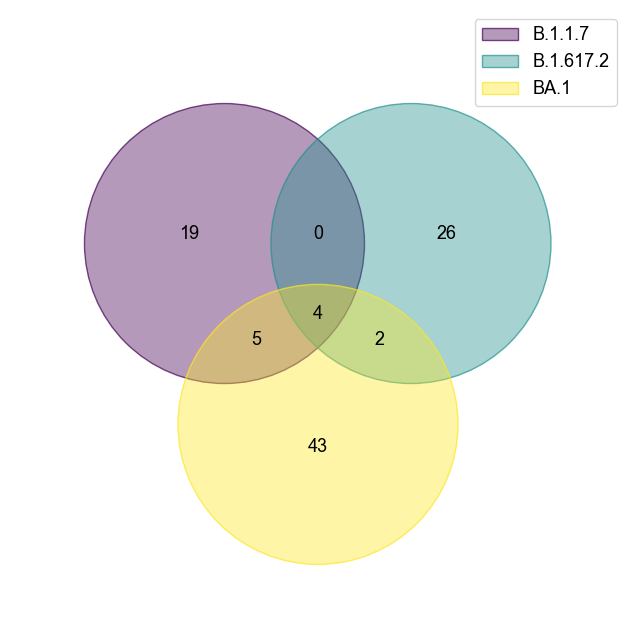

In [12]:
mutation_sets = {v: set(X.index[X[v] == 1]) for v in all_vars}
venn(mutation_sets)

In [12]:
# # RUN ONLY IF YOU WANT TO SAVE THE SIMULATED DATASETS FOR CROSS-VALIDATION
# # Save simulated datasets for the cross validation

# datasets = {
#     "disp1_missing_1_delta_replicator":  datasets["disp1_missing_1"],
#     "disp1_missing_6_delta_replicator":  datasets["disp1_missing_6"],
#     "disp1_missing_10_delta_replicator": datasets["disp1_missing_10"],
#     "disp1_missing_11_delta_replicator": datasets["disp1_missing_11"],

#     "disp2_missing_1_delta_replicator":  datasets["disp2_missing_1"],
#     "disp2_missing_6_delta_replicator":  datasets["disp2_missing_6"],
#     "disp2_missing_10_delta_replicator": datasets["disp2_missing_10"],
#     "disp2_missing_11_delta_replicator": datasets["disp2_missing_11"],

#     "disp3_missing_1_delta_replicator":  datasets["disp3_missing_1"],
#     "disp3_missing_6_delta_replicator":  datasets["disp3_missing_6"],
#     "disp3_missing_10_delta_replicator": datasets["disp3_missing_10"],
#     "disp3_missing_11_delta_replicator": datasets["disp3_missing_11"],
# }

# for name, data in datasets.items():
#     # works for DataFrames and for numpy arrays
#     df = data if isinstance(data, pd.DataFrame) else pd.DataFrame(np.asarray(data))
#     df.to_csv(f"simulated_data/{name}.csv", index=True)          # keeps the row labels (e.g. site names)
#     print(f"saved {name}.csv  shape={df.shape}  NaNs={int(df.isna().sum().sum())}")

saved disp1_missing_1_delta_replicator.csv  shape=(99, 397)  NaNs=0
saved disp1_missing_6_delta_replicator.csv  shape=(99, 397)  NaNs=19792
saved disp1_missing_10_delta_replicator.csv  shape=(99, 397)  NaNs=35333
saved disp1_missing_11_delta_replicator.csv  shape=(99, 397)  NaNs=37300
saved disp2_missing_1_delta_replicator.csv  shape=(99, 397)  NaNs=0
saved disp2_missing_6_delta_replicator.csv  shape=(99, 397)  NaNs=19786
saved disp2_missing_10_delta_replicator.csv  shape=(99, 397)  NaNs=35332
saved disp2_missing_11_delta_replicator.csv  shape=(99, 397)  NaNs=37298
saved disp3_missing_1_delta_replicator.csv  shape=(99, 397)  NaNs=0
saved disp3_missing_6_delta_replicator.csv  shape=(99, 397)  NaNs=19766
saved disp3_missing_10_delta_replicator.csv  shape=(99, 397)  NaNs=35344
saved disp3_missing_11_delta_replicator.csv  shape=(99, 397)  NaNs=37312


                           location  n_variants  lambda_w  lambda_h  lambda_f  mean_error
  disp1_missing_10_delta_replicator           3       9.0      0.30     40.00    0.013024
     disp1_missing_10_genetic_drift           2       0.2      6.00      4.00    0.017828
disp1_missing_10_omicron_replicator           4       0.6      1.00      8.00    0.008114
  disp1_missing_11_delta_replicator           3       5.0      4.00      5.00    0.014676
     disp1_missing_11_genetic_drift           2       0.4     40.00     60.00    0.016783
disp1_missing_11_omicron_replicator           4       0.1      3.00     20.00    0.010984
   disp1_missing_1_delta_replicator           3      20.0      4.00     90.00    0.009995
      disp1_missing_1_genetic_drift           2       0.5      8.00      0.00    0.016379
 disp1_missing_1_omicron_replicator           4       8.0      6.00     10.00    0.007330
   disp1_missing_6_delta_replicator           3      20.0      4.00     70.00    0.009968
      disp

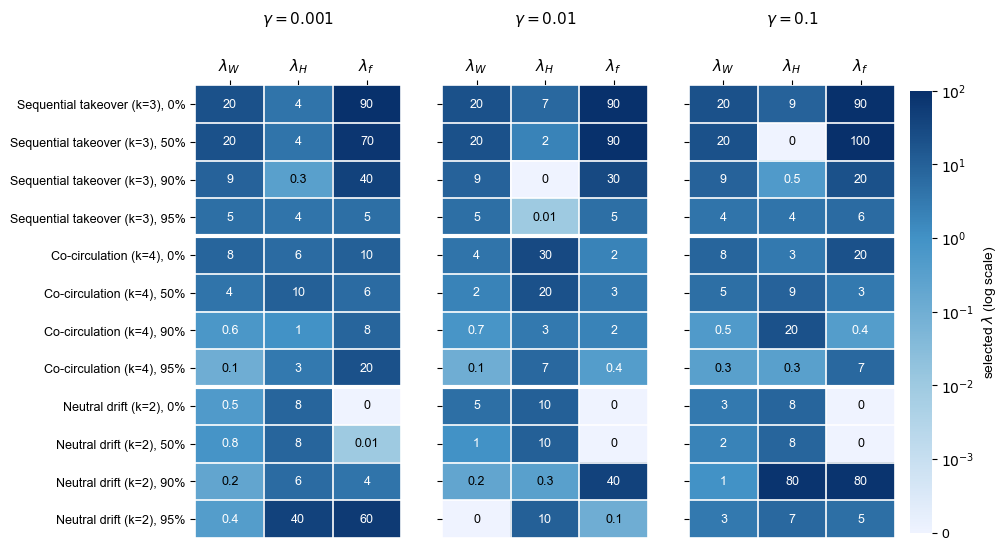

In [13]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LinearSegmentedColormap

CV_CSV = '../results/cross_validation_results/simulations/cross_validation_summary_snv.csv'
FLOOR  = 1e-4                                   # lambda = 0 drawn at this value, labelled "0"
LAMS   = ['lambda_w', 'lambda_h', 'lambda_f']
COLLAB = [r'$\lambda_W$', r'$\lambda_H$', r'$\lambda_f$']

TRUE_RANK = {'delta_replicator': 3, 'omicron_replicator': 4, 'genetic_drift': 2}
SCEN  = {'delta_replicator': 'Sequential takeover', 'omicron_replicator': 'Co-circulation',
         'genetic_drift': 'Neutral drift'}
MISS  = {1: '0%', 6: '50%', 10: '90%', 11: '95%'}        # CHECK: mapping of file index to missing level
NOISE = {1: r'$\gamma=0.001$', 2: r'$\gamma=0.01$', 3: r'$\gamma=0.1$'}   # CHECK: disp1/2/3 -> gamma

cv = pd.read_csv(CV_CSV).dropna(subset=['mean_error'])
info = cv['location'].str.extract(r'disp(\d+)_missing_(\d+)_(.+)')
cv['noise'], cv['miss'], cv['scen'] = info[0].astype(int), info[1].astype(int), info[2]

# optimal lambdas at the true number of variants
at   = cv[cv['n_variants'] == cv['scen'].map(TRUE_RANK)]
best = at.loc[at.groupby('location')['mean_error'].idxmin()]
tab  = best[['location', 'n_variants'] + LAMS + ['mean_error']].sort_values('location')
print(tab.to_string(index=False))
tab.to_csv('optimal_lambdas_true_rank.csv', index=False)

# grid of rows (scenario x missing) per noise level; missing results stay NaN
rows = [(s, m) for s in TRUE_RANK for m in MISS]
B = best.set_index(['noise', 'scen', 'miss'])
def block(n):
    return np.array([B.loc[(n, s, m), LAMS].values.astype(float) if (n, s, m) in B.index
                     else [np.nan] * 3 for s, m in rows])

noises = sorted(NOISE)
vmax = np.log10(max(best[LAMS].values.max(), FLOOR * 10))
norm = Normalize(np.log10(FLOOR), vmax)
cmap = LinearSegmentedColormap.from_list('lam', ['#EFF3FF', '#9ECAE1', '#4292C6', '#08306B'])
cmap.set_bad('#F0F0F0')

with mpl.rc_context({'font.family': 'sans-serif',
                     'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
                     'mathtext.fontset': 'dejavusans'}):
    fig, axes = plt.subplots(1, 3, figsize=(9.5, 0.34 * len(rows) + 1.8), sharey=True)
    for ax, n in zip(axes, noises):
        vals = block(n)
        z = np.ma.masked_invalid(np.log10(np.maximum(vals, FLOOR)))
        im = ax.imshow(z, cmap=cmap, norm=norm, aspect='auto')
        for i in range(len(rows)):
            for j in range(3):
                if np.isnan(vals[i, j]):
                    ax.text(j, i, '–', ha='center', va='center', color='#999999', fontsize=9)
                else:
                    ax.text(j, i, f"{vals[i, j]:g}", ha='center', va='center', fontsize=9,
                            color='white' if norm(z[i, j]) > 0.6 else 'black')
        ax.set_xticks(np.arange(4) - 0.5, minor=True)
        ax.set_yticks(np.arange(len(rows) + 1) - 0.5, minor=True)
        ax.grid(which='minor', color='white', linewidth=1.2)
        ax.tick_params(which='minor', length=0)
        for k in range(1, len(TRUE_RANK)):                    # thicker line between scenarios
            ax.axhline(k * len(MISS) - 0.5, color='white', linewidth=3)
        ax.set_xticks(range(3)); ax.set_xticklabels(COLLAB, fontsize=11)
        ax.xaxis.tick_top()
        ax.set_title(NOISE[n], fontsize=11, pad=24)
        for sp in ax.spines.values():
            sp.set_visible(False)
    axes[0].set_yticks(range(len(rows)))
    axes[0].set_yticklabels([f"{SCEN[s]} (k={TRUE_RANK[s]}), {MISS[m]}" for s, m in rows], fontsize=9)

    cb = fig.colorbar(im, ax=axes, fraction=0.03, pad=0.02)
    ticks = np.arange(np.ceil(np.log10(FLOOR)), np.floor(vmax) + 1)
    cb.set_ticks(ticks)
    cb.set_ticklabels(['0' if t == np.log10(FLOOR) else f"$10^{{{int(t)}}}$" for t in ticks])
    cb.set_label(r'selected $\lambda$ (log scale)', fontsize=10)
    cb.outline.set_visible(False)

    plt.show()

# Fitness NMF - period 1

In [14]:
simulated_data_cv = pd.read_csv('../results/cross_validation_results/simulations/cross_validation_summary_snv.csv')
TARGET_MISSING_FRACS = {0.0, 0.5, 0.9, 0.95}
RANK = 3                                           # true number of variants (Delta)

selected_tiers  = {t['name'] for t in QUALITY_TIERS if t['missing_frac'] in TARGET_MISSING_FRACS}
datasets_subset = {tier: df for tier, df in datasets.items() if tier in selected_tiers}

#cv_key = lambda tier: tier                         # tier name -> 'location' name in simulated_data_cv
cv_key = lambda tier: f"{tier}_delta_replicator"

# CV-optimal lambdas at rank 3 for every tier
cv = simulated_data_cv.dropna(subset=['mean_error'])
cv = cv[cv['n_variants'] == RANK]
opt_lambdas = {}
for tier in datasets_subset:
    g = cv[cv['location'] == cv_key(tier)]
    if g.empty:
        raise KeyError(f"no CV results at rank {RANK} for '{cv_key(tier)}' -- check cv_key / names")
    b = g.loc[g['mean_error'].idxmin()]
    opt_lambdas[tier] = dict(lambda_w=float(b['lambda_w']), lambda_h=float(b['lambda_h']),
                             lambda_f=float(b['lambda_f']))
    print(f"{tier}: lambda_w={b['lambda_w']:g}, lambda_h={b['lambda_h']:g}, lambda_f={b['lambda_f']:g}"
          f"  (CV error {b['mean_error']:.4g})")

NMF_KWARGS_base = dict(
    masking_option=0, rank=RANK, rel_tol=1e-4, bandwidth=10.0, n_run=10,
    random_state=42, n_jobs=-1, n_mu_steps=1)

nmf_results_fitness_regularized = {}
for tier, df in datasets_subset.items():
    print(f"Running joint_soft_dynamics_nmf (CV-optimal) for tier '{tier}'...")
    nmf_results_fitness_regularized[tier] = joint_soft_dynamics_nmf(
        {'sim': df}, **NMF_KWARGS_base, **opt_lambdas[tier])

nmf_results_unregularized = {}
for tier, df in datasets_subset.items():
    print(f"Running joint_soft_dynamics_nmf (unregularized) for tier '{tier}'...")
    nmf_results_unregularized[tier] = joint_soft_dynamics_nmf(
        {'sim': df}, **NMF_KWARGS_base, lambda_w=0, lambda_h=0, lambda_f=0)

disp1_missing_1: lambda_w=20, lambda_h=4, lambda_f=90  (CV error 0.009995)
disp1_missing_6: lambda_w=20, lambda_h=4, lambda_f=70  (CV error 0.009968)
disp1_missing_10: lambda_w=9, lambda_h=0.3, lambda_f=40  (CV error 0.01302)
disp1_missing_11: lambda_w=5, lambda_h=4, lambda_f=5  (CV error 0.01468)
disp2_missing_1: lambda_w=20, lambda_h=7, lambda_f=90  (CV error 0.01068)
disp2_missing_6: lambda_w=20, lambda_h=2, lambda_f=90  (CV error 0.01057)
disp2_missing_10: lambda_w=9, lambda_h=0, lambda_f=30  (CV error 0.01032)
disp2_missing_11: lambda_w=5, lambda_h=0.01, lambda_f=5  (CV error 0.01184)
disp3_missing_1: lambda_w=20, lambda_h=9, lambda_f=90  (CV error 0.01635)
disp3_missing_6: lambda_w=20, lambda_h=0, lambda_f=100  (CV error 0.01636)
disp3_missing_10: lambda_w=9, lambda_h=0.5, lambda_f=20  (CV error 0.01668)
disp3_missing_11: lambda_w=4, lambda_h=4, lambda_f=6  (CV error 0.01511)
Running joint_soft_dynamics_nmf (CV-optimal) for tier 'disp1_missing_1'...
Running joint_soft_dynamics_nm

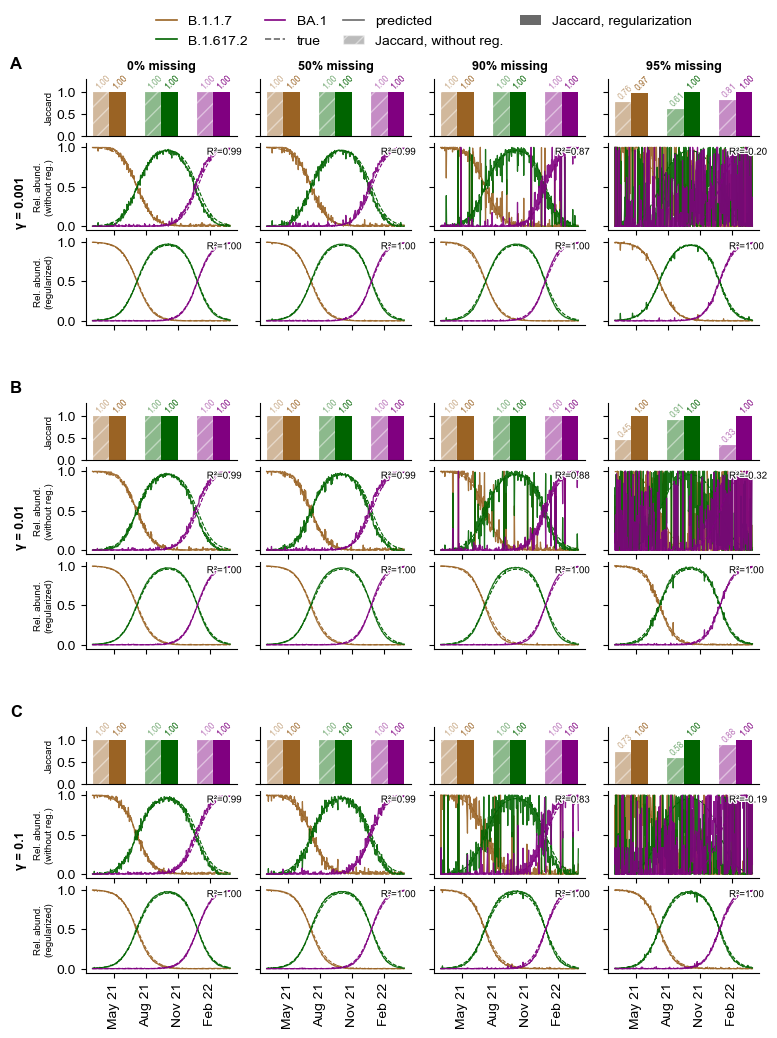

            tier  disp_level  missing_level  gamma  missing_frac  r2_10run  r2_100run  n_variants_matched_10run  n_variants_matched_100run  n_variants_total
 disp1_missing_1           1              1  0.001          0.00  0.992835   0.999306                         3                          3                 3
 disp1_missing_6           1              6  0.001          0.50  0.990703   0.998969                         3                          3                 3
disp1_missing_10           1             10  0.001          0.90  0.867678   0.998063                         3                          3                 3
disp1_missing_11           1             11  0.001          0.95 -0.204141   0.998858                         3                          3                 3
 disp2_missing_1           2              1  0.010          0.00  0.993083   0.999114                         3                          3                 3
 disp2_missing_6           2              6  0.010        

In [15]:
def _r_squared(true_vals, pred_vals):
    true_vals = np.asarray(true_vals, dtype=float)
    pred_vals = np.asarray(pred_vals, dtype=float)
    ss_res = np.sum((true_vals - pred_vals) ** 2)
    ss_tot = np.sum((true_vals - true_vals.mean()) ** 2)
    return np.nan if ss_tot == 0 else 1 - ss_res / ss_tot


def _jaccard_per_variant(result, df, W_covspectrum, all_vars,
                          binarize_threshold, unassigned_threshold):
    """Runs the matching pipeline for one NMF result and returns
    (jaccard_per_variant, best_component_per_variant, label_to_k, H_norm)."""
    rank = result.W.shape[1]
    W_df = pd.DataFrame(result.W, index=list(df.index),
                         columns=[f'Component_{k}' for k in range(rank)])
    W_binary = (W_df >= binarize_threshold).astype(int)

    sim_df, new_labels, best_labels = _match_components_to_ground_truth(
        W_binary, W_covspectrum, unassigned_threshold=unassigned_threshold)
    sim_df.index = new_labels
    label_to_k = {label: k for k, label in enumerate(new_labels)}

    gt_to_pred_labels = {}
    for pred_label, gt_label in zip(new_labels, best_labels):
        gt_to_pred_labels.setdefault(gt_label, []).append(pred_label)

    jaccard_per_variant, best_component_per_variant = {}, {}
    for v in all_vars:
        candidates = gt_to_pred_labels.get(v, [])
        if not candidates:
            jaccard_per_variant[v] = np.nan
            best_component_per_variant[v] = None
            continue
        scores = {pl: sim_df.loc[pl, v] for pl in candidates}
        best_pl = max(scores, key=scores.get)
        jaccard_per_variant[v] = scores[best_pl]
        best_component_per_variant[v] = best_pl

    H_norm = result.H['sim'] / result.H['sim'].sum(axis=0, keepdims=True)
    return jaccard_per_variant, best_component_per_variant, label_to_k, H_norm


def evaluate_and_plot_grid_nature(nmf_results_10, nmf_results_100, datasets,
                                   W_covspectrum, abundance_matrix,
                                   tier_config=None,
                                   binarize_threshold=0.5, unassigned_threshold=0.01,
                                   colors=None, fig_width_mm=183, cell_aspect=1.9):
    all_vars = list(W_covspectrum.columns)
    bar_colors = [colors.get(v, f'C{i}') if colors else f'C{i}' for i, v in enumerate(all_vars)]

    tier_grid = {}
    for tier in nmf_results_100:
        m = re.match(r'disp(\d+)_missing_(\d+)', tier)
        if not m:
            raise ValueError(f"Tier name '{tier}' doesn't match 'dispD_missing_M'.")
        tier_grid[(int(m.group(1)), int(m.group(2)))] = tier

    disp_levels = sorted({d for d, _ in tier_grid})
    missing_levels = sorted({mm for _, mm in tier_grid})
    n_rows, n_cols = len(disp_levels), len(missing_levels)

    row_headers = [f'disp {d}' for d in disp_levels]
    col_headers = [f'missing {mm}' for mm in missing_levels]
    gamma_by_disp, missfrac_by_col = {}, {}
    if tier_config is not None:
        cfg_by_name = {t['name']: t for t in tier_config}
        for (d, mm), name in tier_grid.items():
            cfg = cfg_by_name.get(name)
            if cfg is not None:
                gamma_by_disp[d] = cfg['gamma']
                missfrac_by_col[mm] = cfg['missing_frac']
        row_headers = [f'\u03b3 = {gamma_by_disp[d]:g}' for d in disp_levels]
        col_headers = [f'{missfrac_by_col[mm]*100:.0f}% missing' for mm in missing_levels]

    fig_w_in = fig_width_mm / 25.4
    fig_h_in = fig_w_in / n_cols * n_rows * cell_aspect
    fig = plt.figure(figsize=(fig_w_in, fig_h_in))
    outer = GridSpec(n_rows, n_cols, figure=fig,
                      left=0.06, right=0.995, top=0.92, bottom=0.05,
                      hspace=0.32, wspace=0.15)

    date_locator = mdates.MonthLocator(interval=3)
    date_formatter = mdates.DateFormatter('%b %y')
    r2_records = []
    bar_width = 0.32
    x = np.arange(len(all_vars))

    def _plot_abundance_panel(ax, dates, best_component_per_variant, label_to_k, H_norm):
        true_all, pred_all = [], []
        for i, v in enumerate(all_vars):
            ax.plot(dates, abundance_matrix[:, i], color=bar_colors[i],
                    linestyle='--', linewidth=0.8)
            best_pl = best_component_per_variant[v]
            if best_pl is not None:
                pred_vals = H_norm[label_to_k[best_pl]]
                ax.plot(dates, pred_vals, color=bar_colors[i],
                        linestyle='-', linewidth=0.9, alpha=0.9)
                true_all.append(abundance_matrix[:, i])
                pred_all.append(pred_vals)
        ax.set_ylim(-0.05, 1.05)
        ax.set_yticks([0, 0.5, 1])
        ax.spines[['top', 'right']].set_visible(False)
        r2 = np.nan
        n_matched = len(true_all)
        if true_all:
            r2 = _r_squared(np.concatenate(true_all), np.concatenate(pred_all))
            r2_text = ax.text(0.8, 0.95, f'R\u00b2={r2:.2f}', transform=ax.transAxes,
                               ha='left', va='top', fontsize=7, color='black', zorder=10)
            r2_text.set_path_effects([pe.withStroke(linewidth=2, foreground='white')])
        return r2, n_matched

    for r, disp_i in enumerate(disp_levels):
        for c, missing_j in enumerate(missing_levels):
            tier = tier_grid[(disp_i, missing_j)]
            df = datasets[tier]
            dates = pd.DatetimeIndex(df.columns)

            jacc_10, best_component_10, label_to_k_10, H_norm_10 = _jaccard_per_variant(
                nmf_results_10[tier], df, W_covspectrum, all_vars,
                binarize_threshold, unassigned_threshold)
            jacc_100, best_component_100, label_to_k_100, H_norm_100 = _jaccard_per_variant(
                nmf_results_100[tier], df, W_covspectrum, all_vars,
                binarize_threshold, unassigned_threshold)

            inner = outer[r, c].subgridspec(3, 1, height_ratios=[0.55, 0.85, 0.85], hspace=0.1)
            ax_bar = fig.add_subplot(inner[0])
            ax_ab10 = fig.add_subplot(inner[1])
            ax_ab100 = fig.add_subplot(inner[2])

            ax_bar.bar(x - bar_width / 2, [jacc_10[v] for v in all_vars],
                       width=bar_width, color=bar_colors, alpha=0.45,
                       hatch='//', edgecolor='white', linewidth=0.3)
            ax_bar.bar(x + bar_width / 2, [jacc_100[v] for v in all_vars],
                       width=bar_width, color=bar_colors, linewidth=0)
            ax_bar.set_ylim(0, 1.28)
            ax_bar.set_yticks([0, 0.5, 1])
            ax_bar.set_xticks([])
            ax_bar.spines[['top', 'right']].set_visible(False)
            if c != 0:
                ax_bar.set_yticklabels([])
            for i, v in enumerate(all_vars):
                val10 = jacc_10[v]
                if not np.isnan(val10):
                    ax_bar.text(x[i] - bar_width / 2, val10 + 0.03, f'{val10:.2f}',
                                ha='left', va='bottom', fontsize=6, color=bar_colors[i],
                                alpha=0.55, rotation=45, rotation_mode='anchor')
                val100 = jacc_100[v]
                if not np.isnan(val100):
                    ax_bar.text(x[i] + bar_width / 2, val100 + 0.03, f'{val100:.2f}',
                                ha='left', va='bottom', fontsize=6, color=bar_colors[i],
                                rotation=45, rotation_mode='anchor')

            r2_10, n_matched_10 = _plot_abundance_panel(
                ax_ab10, dates, best_component_10, label_to_k_10, H_norm_10)
            r2_100, n_matched_100 = _plot_abundance_panel(
                ax_ab100, dates, best_component_100, label_to_k_100, H_norm_100)

            ax_ab10.xaxis.set_major_locator(date_locator)
            ax_ab10.set_xticklabels([])
            ax_ab100.xaxis.set_major_locator(date_locator)
            ax_ab100.xaxis.set_major_formatter(date_formatter)
            ax_ab100.tick_params(axis='x', rotation=90)
            if r != n_rows - 1:
                ax_ab100.set_xticklabels([])
            if c != 0:
                ax_ab10.set_yticklabels([])
                ax_ab100.set_yticklabels([])

            r2_records.append(dict(
                tier=tier, disp_level=disp_i, missing_level=missing_j,
                gamma=gamma_by_disp.get(disp_i), missing_frac=missfrac_by_col.get(missing_j),
                r2_10run=r2_10, r2_100run=r2_100,
                n_variants_matched_10run=n_matched_10, n_variants_matched_100run=n_matched_100,
                n_variants_total=len(all_vars),
            ))

            if c == 0:
                ax_bar.set_ylabel('Jaccard', labelpad=2,  fontsize=7)
                ax_ab10.set_ylabel('Rel. abund.\n(without reg.)', labelpad=2, fontsize=7)
                ax_ab100.set_ylabel('Rel. abund.\n(regularized)', labelpad=2, fontsize=7)
            if r == 0:
                ax_bar.set_title(col_headers[c], fontsize=9, pad=7, fontweight='bold')
        pos = outer[r, 0].get_position(fig)
        fig.text(-0.03, pos.y0 + pos.height / 2, row_headers[r],
                  rotation=90, va='center', ha='center', fontsize=9, fontweight='bold')
        fig.text(-0.045, pos.y1 + 0.008, chr(65 + r),
                  fontsize=12, fontweight='bold', ha='left', va='bottom')

    legend_handles = (
        [plt.Line2D([0], [0], color=bar_colors[i], lw=1.2, label=v) for i, v in enumerate(all_vars)]
        + [plt.Line2D([0], [0], color='dimgray', lw=1.2, linestyle='--', label='true'),
           plt.Line2D([0], [0], color='dimgray', lw=1.2, linestyle='-', label='predicted'),
           plt.Rectangle((0, 0), 1, 1, facecolor='dimgray', alpha=0.45, hatch='//',
                          edgecolor='white', label='Jaccard, without reg.'),
           plt.Rectangle((0, 0), 1, 1, facecolor='dimgray', label='Jaccard, regularization')]
    )
    fig.legend(handles=legend_handles, loc='upper center', ncol=4,
               frameon=False, bbox_to_anchor=(0.53, 0.995), handlelength=1.5, columnspacing=1.2)

    r2_df = pd.DataFrame(r2_records)
    return fig, r2_df


fig, r2_table = evaluate_and_plot_grid_nature(
    nmf_results_unregularized, nmf_results_fitness_regularized, datasets,
    W_covspectrum=X, abundance_matrix=abundance_matrix,
    tier_config=QUALITY_TIERS, colors=colors)
fig.savefig('../results/simulated_data/fig_nmf_grid_simulation_1_fitness.pdf', bbox_inches='tight')
plt.show()

print(r2_table.to_string(index=False))
#r2_table.to_csv('r2_estimates_per_tier.csv', index=False)

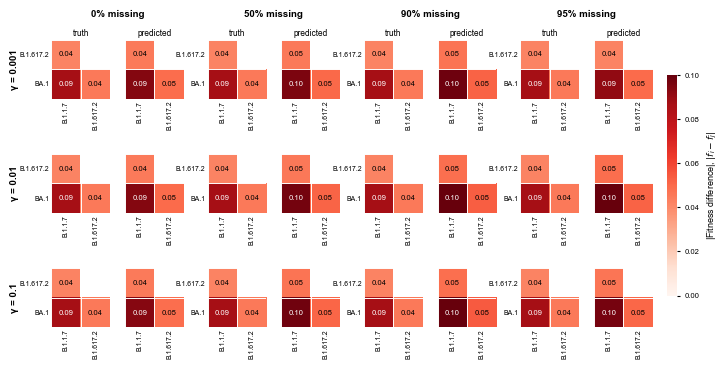

In [16]:
true_fitness = {v: f for v, f in zip(all_vars, f_arr)}


plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

def _lower_tri_submatrix(mat):
    """Trims an (n, n) antisymmetric matrix to its (n-1, n-1) strict lower
    triangle: drops row 0 and the last column (always empty), blanks the
    remaining upper-triangle cells with NaN."""
    n = mat.shape[0]
    sub = mat[1:, :-1].copy()
    n_sub = n - 1
    upper_mask = np.triu(np.ones((n_sub, n_sub), dtype=bool), k=1)
    sub[upper_mask] = np.nan
    return sub


def plot_fitness_diff_heatmaps_grid(nmf_results_100, datasets, W_covspectrum, true_fitness,
                                     tier_config=None, binarize_threshold=0.5, unassigned_threshold=0.01,
                                     fig_width_mm=183, cell_aspect=0.68, cmap='Reds', annot_fontsize=5.5):
    all_vars = list(W_covspectrum.columns)
    n_vars = len(all_vars)
    n_sub = n_vars - 1
    labels_y = all_vars[1:]
    labels_x = all_vars[:-1]

    cmap_obj = plt.get_cmap(cmap).copy()
    cmap_obj.set_bad('white')

    true_vec = np.array([true_fitness.get(v, np.nan) for v in all_vars])
    true_mat = true_vec[:, None] - true_vec[None, :]
    true_sub = _lower_tri_submatrix(true_mat)

    tier_grid = {}
    for tier in nmf_results_100:
        m = re.match(r'disp(\d+)_missing_(\d+)', tier)
        if not m:
            raise ValueError(f"Tier name '{tier}' doesn't match 'dispD_missing_M'.")
        tier_grid[(int(m.group(1)), int(m.group(2)))] = tier

    disp_levels = sorted({d for d, _ in tier_grid})
    missing_levels = sorted({mm for _, mm in tier_grid})
    n_rows, n_cols = len(disp_levels), len(missing_levels)

    row_headers = [f'disp {d}' for d in disp_levels]
    col_headers = [f'missing {mm}' for mm in missing_levels]
    gamma_by_disp, missfrac_by_col = {}, {}
    if tier_config is not None:
        cfg_by_name = {t['name']: t for t in tier_config}
        for (d, mm), name in tier_grid.items():
            cfg = cfg_by_name.get(name)
            if cfg is not None:
                gamma_by_disp[d] = cfg['gamma']
                missfrac_by_col[mm] = cfg['missing_frac']
        row_headers = [f'\u03b3 = {gamma_by_disp[d]:g}' for d in disp_levels]
        col_headers = [f'{missfrac_by_col[mm]*100:.0f}% missing' for mm in missing_levels]

    all_true_abs = np.nanmax(np.abs(true_sub))
    vlim = all_true_abs * 1.15 if all_true_abs > 0 else 1.0

    fig_w_in = fig_width_mm / 25.4
    fig_h_in = fig_w_in / n_cols * n_rows * cell_aspect
    fig = plt.figure(figsize=(fig_w_in, fig_h_in))
    outer = GridSpec(n_rows, n_cols, figure=fig,
                      left=0.065, right=0.90, top=0.87, bottom=0.04,
                      hspace=0.5, wspace=0.18)

    im = None
    for r, disp_i in enumerate(disp_levels):
        for c, missing_j in enumerate(missing_levels):
            tier = tier_grid[(disp_i, missing_j)]
            df = datasets[tier]
            fit_100 = _fitness_per_variant_from_result(
                nmf_results_100[tier], df, W_covspectrum, all_vars,
                binarize_threshold, unassigned_threshold)
            pred_vec = np.array([fit_100[v] for v in all_vars])
            pred_mat = pred_vec[:, None] - pred_vec[None, :]
            pred_sub = _lower_tri_submatrix(pred_mat)

            inner = outer[r, c].subgridspec(1, 2, wspace=0.25)
            ax_true = fig.add_subplot(inner[0])
            ax_pred = fig.add_subplot(inner[1])

            im = ax_true.imshow(np.abs(true_sub), cmap=cmap_obj, vmin=0, vmax=vlim, aspect='equal')
            ax_pred.imshow(np.abs(pred_sub), cmap=cmap_obj, vmin=0, vmax=vlim, aspect='equal')

            for ax, mat, show_ylabels in [(ax_true, true_sub, True), (ax_pred, pred_sub, False)]:
                ax.set_xticks(range(n_sub)); ax.set_yticks(range(n_sub))
                ax.set_xticklabels(labels_x, fontsize=5, rotation=90)
                ax.set_yticklabels(labels_y if show_ylabels else [], fontsize=5)
                ax.tick_params(length=0, pad=1.5)
                ax.set_xticks(np.arange(-.5, n_sub, 1), minor=True)
                ax.set_yticks(np.arange(-.5, n_sub, 1), minor=True)
                ax.grid(which='minor', color='white', linewidth=0.7)
                ax.tick_params(which='minor', length=0)
                for i in range(n_sub):
                    for j in range(n_sub):
                        val = mat[i, j]
                        if not np.isnan(val):
                            txt_color = 'white' if abs(val) > vlim * 0.55 else 'black'
                            ax.text(j, i, f'{val:.2f}', ha='center', va='center',
                                    fontsize=annot_fontsize, color=txt_color)
                for spine in ax.spines.values():
                    spine.set_visible(False)

            if r == 0:
                ax_true.set_title('truth', fontsize=6, pad=3)
                ax_pred.set_title('predicted', fontsize=6, pad=3)
                mid_x = (ax_true.get_position().x0 + ax_pred.get_position().x1) / 2
                fig.text(mid_x, outer[r, c].get_position(fig).y1 + 0.038, col_headers[c],
                          ha='center', fontsize=7, fontweight='bold')

        pos = outer[r, 0].get_position(fig)
        fig.text(0.014, pos.y0 + pos.height / 2, row_headers[r],
                  rotation=90, va='center', ha='center', fontsize=7, fontweight='bold')

    cax = fig.add_axes([0.92, 0.15, 0.014, 0.6])
    cb = fig.colorbar(im, cax=cax)
    cb.set_label('|Fitness difference|, $|f_i - f_j|$', fontsize=6.5)
    cb.ax.tick_params(labelsize=5.5, length=2)
    cb.outline.set_visible(False)

    return fig


fig = plot_fitness_diff_heatmaps_grid(
    nmf_results_fitness_regularized, datasets, W_covspectrum=X, true_fitness=true_fitness,
    tier_config=QUALITY_TIERS)
fig.savefig('../results/simulated_data/fig_fitness_diff_heatmaps_grid_1.pdf', bbox_inches='tight')
plt.show()

                tier  disp  missing_frac  gamma reference_variant  \
0    disp1_missing_1     1          0.00  0.001           B.1.1.7   
1    disp1_missing_6     1          0.50  0.001           B.1.1.7   
2   disp1_missing_10     1          0.90  0.001           B.1.1.7   
3   disp1_missing_11     1          0.95  0.001           B.1.1.7   
4    disp2_missing_1     2          0.00  0.010           B.1.1.7   
5    disp2_missing_6     2          0.50  0.010           B.1.1.7   
6   disp2_missing_10     2          0.90  0.010           B.1.1.7   
7   disp2_missing_11     2          0.95  0.010           B.1.1.7   
8    disp3_missing_1     3          0.00  0.100           B.1.1.7   
9    disp3_missing_6     3          0.50  0.100           B.1.1.7   
10  disp3_missing_10     3          0.90  0.100           B.1.1.7   
11  disp3_missing_11     3          0.95  0.100           B.1.1.7   

    generation_time    mae_pct  
0                 7   5.900944  
1                 7   7.157306  
2  

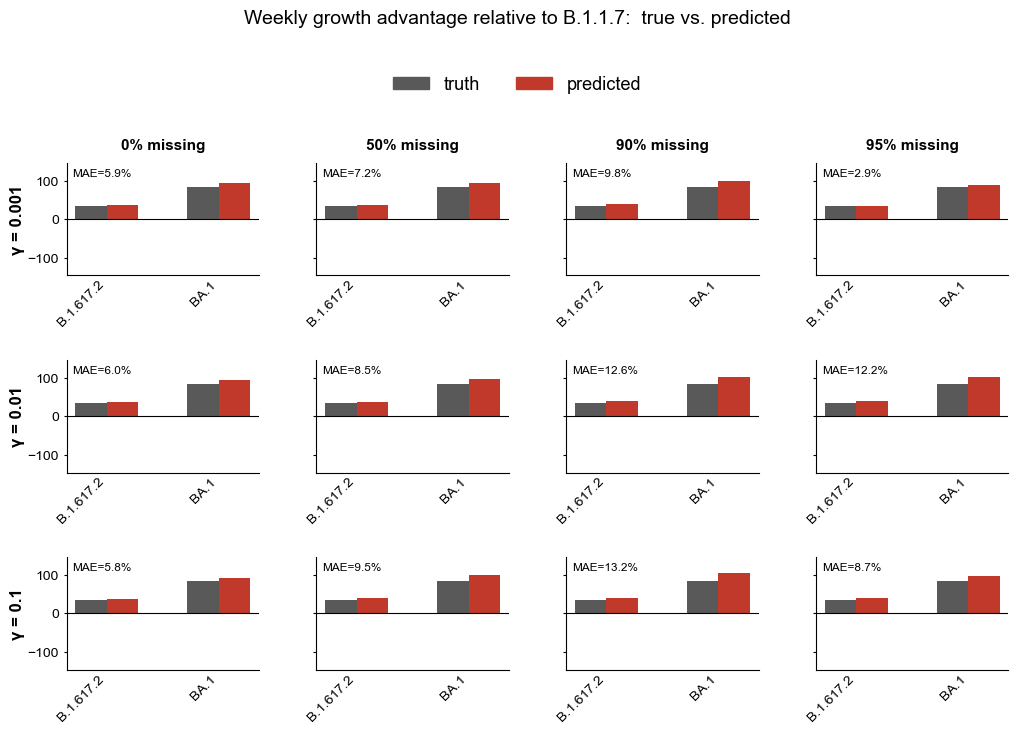

In [17]:
def plot_growth_advantage_bars_grid(nmf_results_100, datasets, W_covspectrum, true_fitness,
                                     reference_variant=None, tier_config=None,
                                     generation_time=1.0,
                                     binarize_threshold=0.5, unassigned_threshold=0.01,
                                     fig_width_mm=260, cell_aspect=1.0,
                                     true_color='0.35', pred_color='#c0392b',
                                     bar_width=0.28,
                                     title_fontsize=11, tick_fontsize=10,
                                     row_header_fontsize=12, suptitle_fontsize=14,
                                     legend_fontsize=13, err_fontsize=8.5):
    """Grid of grouped bar charts comparing true vs. predicted GROWTH ADVANTAGE,
    100*(exp(generation_time*(f_i-f_ref))-1), each expressed relative to a
    single reference variant, across the (gamma x missing_frac) tier grid.
    Each panel is annotated with its own MAE = mean(|pred_adv - true_adv|),
    in percentage points, and a tidy summary_df of per-tier MAE is returned
    alongside the figure. Font sizes are all exposed as parameters so the
    figure can be scaled up for readability without editing the function body."""
    all_vars = list(W_covspectrum.columns)
    if reference_variant is None:
        reference_variant = all_vars[0]
    other_vars = [v for v in all_vars if v != reference_variant]
    n_sub = len(other_vars)
    x = np.arange(n_sub)

    true_ref = true_fitness[reference_variant]
    true_log_diffs = np.array([true_fitness[v] - true_ref for v in other_vars])
    true_adv = 100 * (np.exp(generation_time * true_log_diffs) - 1)

    tier_grid = {}
    for tier in nmf_results_100:
        m = re.match(r'disp(\d+)_missing_(\d+)', tier)
        if not m:
            raise ValueError(f"Tier name '{tier}' doesn't match 'dispD_missing_M'.")
        tier_grid[(int(m.group(1)), int(m.group(2)))] = tier

    disp_levels = sorted({d for d, _ in tier_grid})
    missing_levels = sorted({mm for _, mm in tier_grid})
    n_rows, n_cols = len(disp_levels), len(missing_levels)

    row_headers = [f'disp {d}' for d in disp_levels]
    col_headers = [f'missing {mm}' for mm in missing_levels]
    gamma_by_disp, missfrac_by_col = {}, {}
    if tier_config is not None:
        cfg_by_name = {t['name']: t for t in tier_config}
        for (d, mm), name in tier_grid.items():
            cfg = cfg_by_name.get(name)
            if cfg is not None:
                gamma_by_disp[d] = cfg['gamma']
                missfrac_by_col[mm] = cfg['missing_frac']
        row_headers = [f'\u03b3 = {gamma_by_disp[d]:g}' for d in disp_levels]
        col_headers = [f'{missfrac_by_col[mm]*100:.0f}% missing' for mm in missing_levels]

    pred_adv_by_tier = {}
    for (d, mm), tier in tier_grid.items():
        df = datasets[tier]
        fit_100 = _fitness_per_variant_from_result(
            nmf_results_100[tier], df, W_covspectrum, all_vars,
            binarize_threshold, unassigned_threshold)
        pred_log_diffs = np.array([fit_100[v] - fit_100[reference_variant] for v in other_vars])
        pred_adv_by_tier[tier] = 100 * (np.exp(generation_time * pred_log_diffs) - 1)

    all_vals = np.concatenate([true_adv] + list(pred_adv_by_tier.values()))
    vlim = np.nanmax(np.abs(all_vals)) * 1.4 if np.nanmax(np.abs(all_vals)) > 0 else 1.0

    fig_w_in = fig_width_mm / 25.4
    fig_h_in = fig_w_in / n_cols * n_rows * cell_aspect
    fig = plt.figure(figsize=(fig_w_in, fig_h_in))
    outer = GridSpec(n_rows, n_cols, figure=fig,
                      left=0.06, right=0.98, top=0.82, bottom=0.16,
                      hspace=0.75, wspace=0.3)

    summary = []

    for r, disp_i in enumerate(disp_levels):
        for c, missing_j in enumerate(missing_levels):
            tier = tier_grid[(disp_i, missing_j)]
            pred_adv = pred_adv_by_tier[tier]
            mae_tier = np.mean(np.abs(pred_adv - true_adv))
            summary.append({
                'tier': tier, 'disp': disp_i,
                'missing_frac': missfrac_by_col.get(missing_j, missing_j),
                'gamma': gamma_by_disp.get(disp_i, np.nan),
                'reference_variant': reference_variant,
                'generation_time': generation_time,
                'mae_pct': mae_tier,
            })

            ax = fig.add_subplot(outer[r, c])
            ax.bar(x - bar_width / 2, true_adv, bar_width, color=true_color, label='truth')
            ax.bar(x + bar_width / 2, pred_adv, bar_width, color=pred_color, label='predicted')
            ax.axhline(0, color='black', linewidth=0.8)
            ax.set_ylim(-vlim, vlim)
            ax.set_xticks(x)
            ax.set_xticklabels(other_vars, fontsize=tick_fontsize, rotation=45, ha='right')
            ax.tick_params(axis='y', labelsize=tick_fontsize, length=2)
            ax.tick_params(axis='x', length=0, pad=2)
            if c != 0:
                ax.set_yticklabels([])
            for spine in ['top', 'right']:
                ax.spines[spine].set_visible(False)

            ax.text(0.03, 0.95, f'MAE={mae_tier:.1f}%', transform=ax.transAxes,
                     ha='left', va='top', fontsize=err_fontsize, color='black')

            if r == 0:
                ax.set_title(col_headers[c], fontsize=title_fontsize, fontweight='bold', pad=10)

        pos = outer[r, 0].get_position(fig)
        fig.text(0.012, pos.y0 + pos.height / 2, row_headers[r],
                  rotation=90, va='center', ha='center', fontsize=row_header_fontsize,
                  fontweight='bold')

    fig.suptitle(f'Weekly growth advantage relative to {reference_variant}: '
                 f' true vs. predicted',
                 fontsize=suptitle_fontsize, y=1.02)

    handles = [plt.Rectangle((0, 0), 1, 1, color=true_color), plt.Rectangle((0, 0), 1, 1, color=pred_color)]
    fig.legend(handles, ['truth', 'predicted'], loc='upper center', bbox_to_anchor=(0.5, 0.955),
               ncol=2, fontsize=legend_fontsize, frameon=False)

    summary_df = pd.DataFrame(summary)
    return summary_df, fig


summary_df, fig = plot_growth_advantage_bars_grid(
    nmf_results_fitness_regularized, datasets, W_covspectrum=X, true_fitness=true_fitness,
    tier_config=QUALITY_TIERS, reference_variant='B.1.1.7', generation_time=7)
fig.savefig('../results/simulated_data/fig_growth_advantage_bars_grid_1.pdf', bbox_inches='tight')
print(summary_df)
plt.show()

# Simulate Omicron lineages

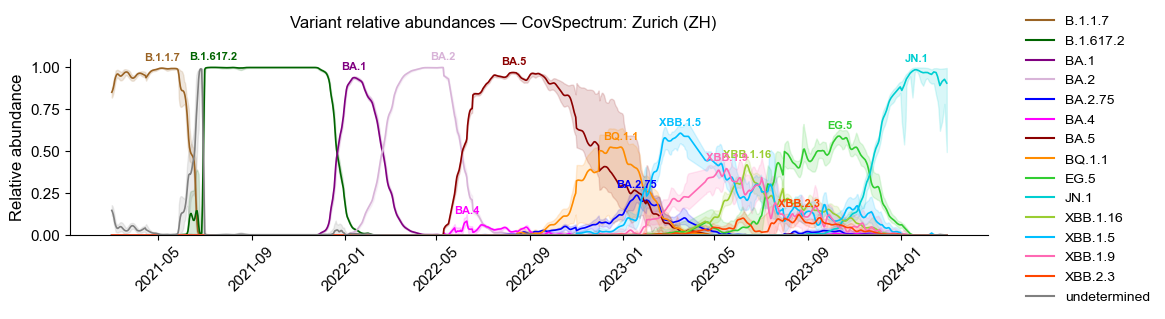

In [18]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

with open("../data/public_wastewater_data_share/ww_update_data_combined.json", 'r') as f:
    data = json.load(f)

# ── Parse ─────────────────────────────────────────────────────────────────────
rows = []
for loc, variants_dict in data.items():
    for variant, inner in variants_dict.items():

        # handle both list and dict with timeseriesSummary
        if isinstance(inner, list):
            records = inner
        elif isinstance(inner, dict) and 'timeseriesSummary' in inner:
            records = inner['timeseriesSummary']
        else:
            records = list(inner.values())[0] if inner else []

        for rec in records:
            rows.append({
                'location':        loc,
                'variant':         variant,
                'date':            pd.to_datetime(rec['date']),
                'proportion':      rec.get('proportion',      np.nan),
                'proportionLower': rec.get('proportionLower', np.nan),
                'proportionUpper': rec.get('proportionUpper', np.nan)
            })

df = pd.DataFrame(rows).sort_values(['location', 'variant', 'date'])
# ── Filter date range ─────────────────────────────────────────────────────────
df = df[
    (df['date'] >= '2021-03-01') &
    (df['date'] <= '2024-03-01')]
# Filter the location
df = df[df['location'] == 'Zürich (ZH)']

# print(f"Locations: {df['location'].unique()}")
# print(f"Variants:  {df['variant'].unique()}")
# print(f"Shape:     {df.shape}")

# ── Plot ──────────────────────────────────────────────────────────────────────

locations = sorted(df['location'].unique())

# ── CovSpectrum-style colors ──────────────────────────────────────────────────
covspectrum_colors = {
    'undetermined': '#808080',
    'B.1.1.7':   '#9a6324',  # grey
    'B.1.351':   '#ff0000',  # red
    'P.1':       '#00ff00',  # bright green
    'B.1.617.2': '#006400',  # dark green
    'BA.1':      '#800080',  # purple
    'BA.2':      '#d8b4d8',  # light purple/lavender
    'BA.2.75':   '#0000ff',  # blue
    'BA.4':      '#ff00ff',  # magenta
    'BA.5':      '#8b0000',  # dark red/brown
    'BQ.1.1':    '#ff8c00',  # orange
    'XBB.1.5':   '#00bfff',  # light blue
    'XBB.1.9':   '#ff69b4',  # pink
    'XBB.1.16':  '#9acd32',  # yellow green
    'XBB.2.3':   '#ff4500',  # red orange
    'EG.5':      '#32cd32',  # lime green
    'BA.2.86':   '#8b4513',  # brown
    'JN.1':      '#00ced1',  # dark turquoise
    'KP.2':      '#4169e1',  # royal blue
    'KP.3':      '#9400d3',  # dark violet
}

# ── Fallback for variants not in dict ────────────────────────────────────────
fallback_colors = [
    '#e6194b', '#3cb44b', '#4363d8', '#f58231', '#911eb4',
    '#42d4f4', '#f032e6', '#bfef45', '#469990', '#9a6324',
]

def get_color(variant, idx):
    if variant in covspectrum_colors:
        return covspectrum_colors[variant]
    return fallback_colors[idx % len(fallback_colors)]

variants = sorted(df['variant'].unique())
colors   = {v: get_color(v, i) for i, v in enumerate(variants)}



fig, axes = plt.subplots(len(locations), 1,
                          figsize=(10, 3),
                          sharex=True)

if len(locations) == 1:
    axes = [axes]

# ── Filter variants that appeared above x % for at least y days ───────────────
def variant_appeared(df_v, threshold=0.05, min_days=10):
    return (df_v['proportion'] > threshold).sum() >= min_days

for ax, loc in zip(axes, locations):
    df_loc = df[df['location'] == loc]

    for variant in variants:
        df_v = df_loc[df_loc['variant'] == variant].sort_values('date')

        if df_v.empty:
            continue

        # ── Skip if never above x% for y+ days ───────────────────────────────
        if not variant_appeared(df_v):
            continue

        color = colors[variant]
        ax.plot(df_v['date'], df_v['proportion'],
                color=color, linewidth=1.2)

        if not df_v['proportionLower'].isna().all():
            ax.fill_between(df_v['date'],
                            df_v['proportionLower'],
                            df_v['proportionUpper'],
                            color=color, alpha=0.15)

        # ── Label at peak ─────────────────────────────────────────────────────
        peak_idx = df_v['proportion'].idxmax()
        peak_x   = df_v.loc[peak_idx, 'date']
        peak_y   = df_v.loc[peak_idx, 'proportion']

        if peak_y > 0.05 and variant != 'undetermined':
            ax.annotate(
                variant,
                xy=(peak_x, peak_y),
                xytext=(0, 4),
                textcoords='offset points',
                ha='center', va='bottom',
                fontsize=8,
                color=color,
                fontweight='bold')

    ax.set_ylabel('Relative abundance', fontsize=12)
    #ax.set_title('Zürich (ZH)', fontsize=15)
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis='x', rotation=45, labelsize=11)
    ax.tick_params(axis='y', labelsize=11)
    ax.spines[['top', 'right']].set_visible(False)



# ── Build legend only for variants that appeared in at least one location ─────
active_variants = []
for variant in variants:
    df_v = df[df['variant'] == variant]
    if variant_appeared(df_v):
        active_variants.append(variant)

# ── Legend — only active variants ────────────────────────────────────────────
handles = [plt.Line2D([0], [0], color=colors[v], linewidth=1.5, label=v)
           for v in active_variants]  


fig.legend(handles=handles,
           bbox_to_anchor=(1.01, 0.5),
           loc='center left',
           fontsize=10, frameon=False)


plt.suptitle('Variant relative abundances — CovSpectrum: Zurich (ZH)', fontsize=12)
plt.tight_layout()
#plt.savefig('results/lollipop_covspectrum_abundances.pdf', bbox_inches='tight')
plt.show()

[  0.          -5.377914    -4.94507094 -11.51926928] [0.         0.02937366 0.02809965 0.06379221] ['BA.5', 'BA.2.75', 'BQ.1.1', 'XBB.1.5'] 2022-08-01 00:00:00


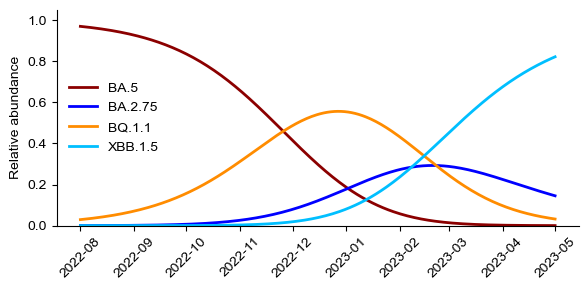

In [19]:
variants   = ['BA.2.75', 'BQ.1.1', 'XBB.1.5']

ref_variant = 'BA.5'
date_start, date_end = '2022-08-01', '2023-05-01'

b_arr, f_arr, all_vars, t0 = fit_multi_variant_window(
    df, 'Zürich (ZH)', variants, ref_variant, date_start, date_end)
print(b_arr, f_arr, all_vars, t0)
b_arr = [0.0, -8,  -3.5, -12]
f_arr = [-0.0,  0.052, 0.03, 0.073]

date_range = pd.date_range(date_start, date_end)
P_sim = simulate_logistic_growth_multi(date_range, t0, b_arr, f_arr)

fig, ax = plt.subplots(figsize=(6, 3))
for i, var in enumerate(all_vars):
    obs = df[(df['location'] == 'Zürich (ZH)') & (df['variant'] == var) &
             (df['date'] >= date_start) & (df['date'] <= date_end)].set_index('date')['proportion']
    color = colors.get(var, f'C{i}')
    ax.plot(date_range, P_sim[:, i], color=color, linewidth=2, label=var)

ax.set_ylabel('Relative abundance'); ax.set_ylim(0, 1.05)
ax.spines[['top', 'right']].set_visible(False)
ax.tick_params(axis='x', rotation=45)
ax.legend(frameon=False, fontsize=10, ncol=1)
plt.tight_layout()
#plt.savefig('results/fitted_multi_variant_window.pdf', bbox_inches='tight')
plt.show()

In [20]:
X = W_covspectrum[all_vars].copy()
X = X.loc[X.sum(axis=1) > 0]          # drop mutations absent from all 3 variants

abundance_matrix = P_sim
dates = date_range
mutation_freq = X.values @ abundance_matrix.T

In [21]:
# ── Noise injection (varies by quality group) ────────────────────────────────────
def simulate_observed(mutation_freq, dates, index,
                       mu, sigma2_depth, gamma,
                       delta, missing_frac, seed=42):
    rng = np.random.default_rng(seed)
    y = (mutation_freq + delta) / (1 + 2 * delta)

    r = mu**2 / (sigma2_depth - mu)
    p = mu / sigma2_depth
    depth = nbinom.rvs(r, p, size=y.shape, random_state=rng)
    depth = np.maximum(depth, 1)

    y_observed = betabinom.rvs(depth, y * (1 - gamma)/gamma, (1 - y)*(1-gamma)/gamma,
                                random_state=rng) / depth
    y_observed_missing = y_observed.copy()
    y_observed_missing[rng.random(y_observed.shape) < missing_frac] = np.nan

    df = pd.DataFrame(y_observed_missing, index=index, columns=dates)
    depth_df = pd.DataFrame(depth, index=index, columns=dates)
    return df, depth_df


# # ── Quality tiers: best -> worst ─────────────────────────────────────────────────
# QUALITY_TIERS = [
#     dict(name='disp1_missing_1',   mu=6.7e4, sigma2_depth=2.5e10, gamma=0.001, delta=0.0025, missing_frac=0.0),
#     dict(name='disp2_missing_1', mu=6.7e4, sigma2_depth=2.5e10,  gamma=0.01,  delta=0.0025, missing_frac=0.0),
#     dict(name='disp3_missing_1',  mu=6.7e4, sigma2_depth=2.5e10,   gamma=0.1,   delta=0.0025, missing_frac=0.0),
#     dict(name='disp1_missing_2',   mu=6.7e4, sigma2_depth=2.5e10, gamma=0.001, delta=0.0025, missing_frac=0.5),
#     dict(name='disp2_missing_2', mu=6.7e4, sigma2_depth=2.5e10,  gamma=0.01,  delta=0.0025, missing_frac=0.5),
#     dict(name='disp3_missing_2',  mu=6.7e4, sigma2_depth=2.5e10,   gamma=0.1,   delta=0.0025, missing_frac=0.5),
#     dict(name='disp1_missing_3',   mu=6.7e4, sigma2_depth=2.5e10, gamma=0.001, delta=0.0025, missing_frac=0.90),
#     dict(name='disp2_missing_3', mu=6.7e4, sigma2_depth=2.5e10,  gamma=0.01,  delta=0.0025, missing_frac=0.90),
#     dict(name='disp3_missing_3',  mu=6.7e4, sigma2_depth=2.5e10,   gamma=0.1,   delta=0.0025, missing_frac=0.90),
#     dict(name='disp1_missing_4',   mu=6.7e4, sigma2_depth=2.5e10, gamma=0.001, delta=0.0025, missing_frac=0.95),
#     dict(name='disp2_missing_4', mu=6.7e4, sigma2_depth=2.5e10,  gamma=0.01,  delta=0.0025, missing_frac=0.95),
#     dict(name='disp3_missing_4',  mu=6.7e4, sigma2_depth=2.5e10,   gamma=0.1,   delta=0.0025, missing_frac=0.95),
# ]

# ── Quality tiers: best -> worst ─────────────────────────────────────────────────
gammas = [0.001, 0.01, 0.1]
missing_fracs = [round(m / 10, 2) for m in range(10)] + [0.95]  # 0.0, 0.1, 0.2, ..., 0.9

QUALITY_TIERS = [
    dict(name=f'disp{d_idx+1}_missing_{m_idx+1}',
         mu=6.7e4, sigma2_depth=2.5e10, gamma=gamma, delta=0.0025, missing_frac=mf)
    for d_idx, gamma in enumerate(gammas)
    for m_idx, mf in enumerate(missing_fracs)
]

def build_quality_datasets(X, abundance_matrix, mutation_freq, dates,
                            seed=42, quality_tiers=QUALITY_TIERS):
    """
    Simulate one observed dataset per quality tier from an already-built
    ground truth (X, abundance_matrix, mutation_freq, dates) -- ground
    truth is no longer built inside this function.

    Returns
    -------
    X, abundance_matrix : passed through unchanged (kept in the return
        signature so downstream code doesn't need to track them separately)
    datasets : dict[str, pd.DataFrame]
        quality tier name -> observed mutation-frequency DataFrame (with NaNs)
    """
    datasets = {}
    for tier in quality_tiers:
        df, _depth_df = simulate_observed(
            mutation_freq, dates, X.index,
            mu=tier['mu'], sigma2_depth=tier['sigma2_depth'], gamma=tier['gamma'],
            delta=tier['delta'], missing_frac=tier['missing_frac'],
            seed=seed)
        datasets[tier['name']] = df

    return X, abundance_matrix, datasets


if __name__ == '__main__':
    # X, abundance_matrix, mutation_freq, dates come from
    # simulate_ground_truth_sequential_takeover(...), already computed
    X, abundance_matrix, datasets = build_quality_datasets(X, abundance_matrix, mutation_freq, dates)

    print("Quality datasets summary:")
    for name, df in datasets.items():
        pct_missing = df.isna().mean().mean() * 100
        mean_val = df.stack().mean()
        print(f"  {name}: {pct_missing:5.1f}% missing, mean observed freq = {mean_val:.4f}")

Quality datasets summary:
  disp1_missing_1:   0.0% missing, mean observed freq = 0.6421
  disp1_missing_2:  10.1% missing, mean observed freq = 0.6426
  disp1_missing_3:  20.4% missing, mean observed freq = 0.6418
  disp1_missing_4:  30.3% missing, mean observed freq = 0.6398
  disp1_missing_5:  40.1% missing, mean observed freq = 0.6397
  disp1_missing_6:  50.0% missing, mean observed freq = 0.6399
  disp1_missing_7:  60.2% missing, mean observed freq = 0.6393
  disp1_missing_8:  70.2% missing, mean observed freq = 0.6397
  disp1_missing_9:  80.1% missing, mean observed freq = 0.6421
  disp1_missing_10:  90.0% missing, mean observed freq = 0.6347
  disp1_missing_11:  94.9% missing, mean observed freq = 0.6383
  disp2_missing_1:   0.0% missing, mean observed freq = 0.6426
  disp2_missing_2:  10.1% missing, mean observed freq = 0.6435
  disp2_missing_3:  20.4% missing, mean observed freq = 0.6420
  disp2_missing_4:  30.3% missing, mean observed freq = 0.6433
  disp2_missing_5:  40.1% m

<Axes: >

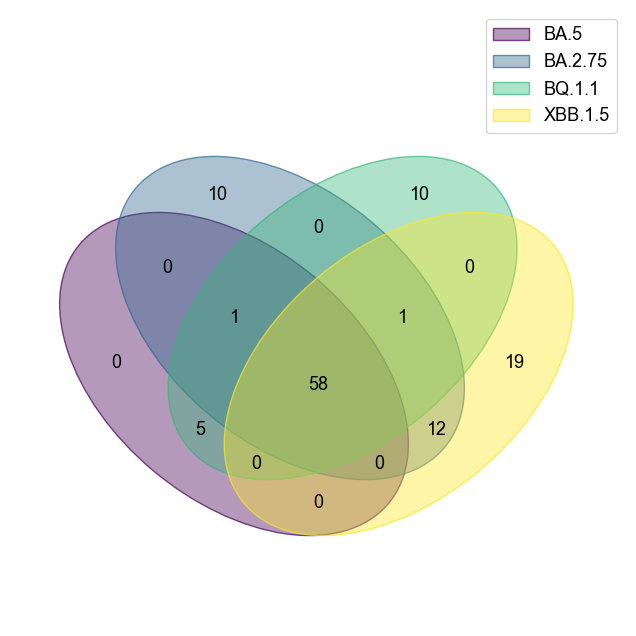

In [22]:
mutation_sets = {v: set(X.index[X[v] == 1]) for v in all_vars}
venn(mutation_sets)

In [19]:
# # ONLY run this once to generate the datasets, then comment it out
# # Save simulated datasets for the cross validation

# import numpy as np
# import pandas as pd

# datasets = {
#     "disp1_missing_1_omicron_replicator":  datasets["disp1_missing_1"],
#     "disp1_missing_6_omicron_replicator":  datasets["disp1_missing_6"],
#     "disp1_missing_10_omicron_replicator": datasets["disp1_missing_10"],
#     "disp1_missing_11_omicron_replicator": datasets["disp1_missing_11"],

#     "disp2_missing_1_omicron_replicator":  datasets["disp2_missing_1"],
#     "disp2_missing_6_omicron_replicator":  datasets["disp2_missing_6"],
#     "disp2_missing_10_omicron_replicator": datasets["disp2_missing_10"],
#     "disp2_missing_11_omicron_replicator": datasets["disp2_missing_11"],

#     "disp3_missing_1_omicron_replicator":  datasets["disp3_missing_1"],
#     "disp3_missing_6_omicron_replicator":  datasets["disp3_missing_6"],
#     "disp3_missing_10_omicron_replicator": datasets["disp3_missing_10"],
#     "disp3_missing_11_omicron_replicator": datasets["disp3_missing_11"],
# }

# for name, data in datasets.items():
#     # works for DataFrames and for numpy arrays
#     df = data if isinstance(data, pd.DataFrame) else pd.DataFrame(np.asarray(data))
#     df.to_csv(f"simulated_data/{name}.csv", index=True)          # keeps the row labels (e.g. site names)
#     print(f"saved {name}.csv  shape={df.shape}  NaNs={int(df.isna().sum().sum())}")

saved disp1_missing_1_omicron_replicator.csv  shape=(116, 274)  NaNs=0
saved disp1_missing_6_omicron_replicator.csv  shape=(116, 274)  NaNs=15888
saved disp1_missing_10_omicron_replicator.csv  shape=(116, 274)  NaNs=28610
saved disp1_missing_11_omicron_replicator.csv  shape=(116, 274)  NaNs=30159
saved disp2_missing_1_omicron_replicator.csv  shape=(116, 274)  NaNs=0
saved disp2_missing_6_omicron_replicator.csv  shape=(116, 274)  NaNs=15872
saved disp2_missing_10_omicron_replicator.csv  shape=(116, 274)  NaNs=28595
saved disp2_missing_11_omicron_replicator.csv  shape=(116, 274)  NaNs=30152
saved disp3_missing_1_omicron_replicator.csv  shape=(116, 274)  NaNs=0
saved disp3_missing_6_omicron_replicator.csv  shape=(116, 274)  NaNs=15879
saved disp3_missing_10_omicron_replicator.csv  shape=(116, 274)  NaNs=28609
saved disp3_missing_11_omicron_replicator.csv  shape=(116, 274)  NaNs=30196


# Select the number of variants

            tier  gamma  missing_frac  K_true  K_selected  correct
 disp1_missing_1  0.001          0.00       3           3     True
 disp1_missing_6  0.001          0.50       3           3     True
disp1_missing_10  0.001          0.90       3           3     True
disp1_missing_11  0.001          0.95       3           3     True
 disp2_missing_1  0.010          0.00       3           3     True
 disp2_missing_6  0.010          0.50       3           3     True
disp2_missing_10  0.010          0.90       3           3     True
disp2_missing_11  0.010          0.95       3           4    False
 disp3_missing_1  0.100          0.00       3           3     True
 disp3_missing_6  0.100          0.50       3           3     True
disp3_missing_10  0.100          0.90       3           3     True
disp3_missing_11  0.100          0.95       3           3     True


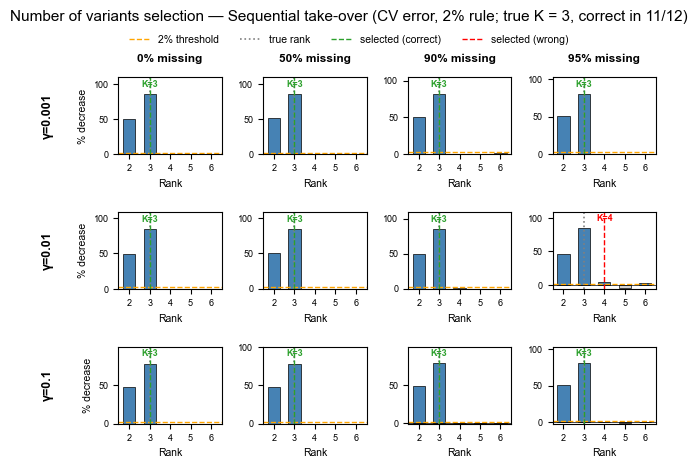

            tier  gamma  missing_frac  K_true  K_selected  correct
 disp1_missing_1  0.001          0.00       4           4     True
 disp1_missing_6  0.001          0.50       4           4     True
disp1_missing_10  0.001          0.90       4           4     True
disp1_missing_11  0.001          0.95       4           3    False
 disp2_missing_1  0.010          0.00       4           4     True
 disp2_missing_6  0.010          0.50       4           4     True
disp2_missing_10  0.010          0.90       4           4     True
disp2_missing_11  0.010          0.95       4           3    False
 disp3_missing_1  0.100          0.00       4           4     True
 disp3_missing_6  0.100          0.50       4           4     True
disp3_missing_10  0.100          0.90       4           3    False
disp3_missing_11  0.100          0.95       4           3    False


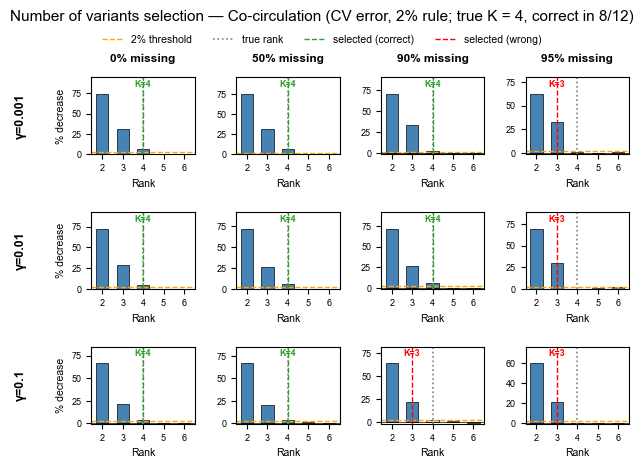

            tier  gamma  missing_frac  K_true  K_selected  correct
 disp1_missing_1  0.001          0.00       2           2     True
 disp1_missing_6  0.001          0.50       2           2     True
disp1_missing_10  0.001          0.90       2           2     True
disp1_missing_11  0.001          0.95       2           1    False
 disp2_missing_1  0.010          0.00       2           2     True
 disp2_missing_6  0.010          0.50       2           2     True
disp2_missing_10  0.010          0.90       2           1    False
disp2_missing_11  0.010          0.95       2           1    False
 disp3_missing_1  0.100          0.00       2           2     True
 disp3_missing_6  0.100          0.50       2           2     True
disp3_missing_10  0.100          0.90       2           2     True
disp3_missing_11  0.100          0.95       2           2     True


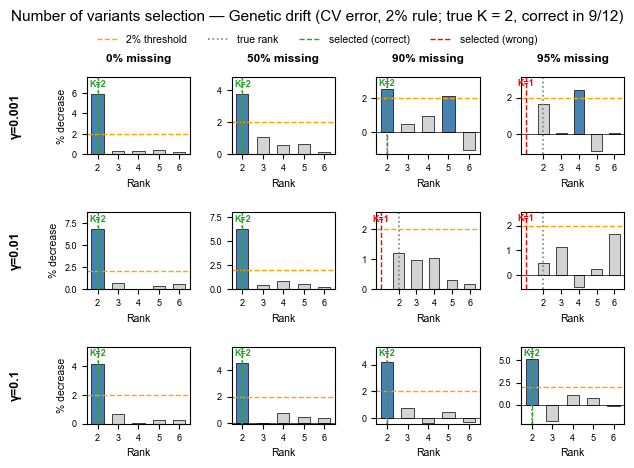

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TRUE_RANK = {'delta': 3, 'omicron': 4, 'drift': 2}


def plot_cv_elbow_grid(cv_results, tier_config, scenario, label=None, output_path=None,
                       thr_pct=2.0, panel_w=1.6, panel_h=1.5):
    """Same layout as plot_elbow_grid (rows = gamma, columns = missing fraction), but on the CV error:
       for every tier and rank the best lambda combination is taken from `cv_results`
       (location = '<tier>_<scenario>'), the bars show the % decrease of the CV error per rank,
       the selected rank (last rank before the decrease first drops below thr_pct) is green if it
       equals the true rank and red otherwise; the true rank is a grey dotted line."""
    k_true = next(r for k, r in TRUE_RANK.items() if k in scenario)

    # ── CV error at the CV-optimal lambdas, per tier and rank ────────────────
    cv = cv_results[cv_results['location'].str.endswith(f'_{scenario}')].dropna(subset=['mean_error'])
    best = cv.loc[cv.groupby(['location', 'n_variants'])['mean_error'].idxmin()]
    elbow = pd.DataFrame({'tier': best['location'].str[:-len(scenario) - 1].values,
                          'rank': best['n_variants'].astype(int).values,
                          'cv_error': best['mean_error'].values})

    tiers_with_data = set(elbow['tier'])
    present = [t for t in tier_config if t['name'] in tiers_with_data]     # only quality levels with CV results
    if not present:
        raise ValueError(f"no CV results for any tier of '{scenario}' (names: '<tier>_{scenario}')")
    gammas = sorted(set(t['gamma'] for t in present))
    missing_fracs = sorted(set(t['missing_frac'] for t in present))
    tier_lookup = {(t['gamma'], t['missing_frac']): t['name'] for t in present}

    n_rows, n_cols = len(gammas), len(missing_fracs)
    fig = plt.figure(figsize=(panel_w * n_cols, panel_h * n_rows))
    outer = fig.add_gridspec(n_rows, n_cols, wspace=0.4, hspace=0.75, left=0.14, right=0.98)

    summary, row_header_info = [], []
    for r, gamma in enumerate(gammas):
        for c, missing_frac in enumerate(missing_fracs):
            tier_name = tier_lookup.get((gamma, missing_frac))
            ax = fig.add_subplot(outer[r, c])
            if tier_name is None:                      # combination not simulated: leave the cell empty
                ax.axis('off')
                if c == 0:
                    row_header_info.append((ax, gamma))
                if r == 0:
                    ax.annotate(f'{missing_frac * 100:.0f}% missing', xy=(0.5, 1.18), xycoords='axes fraction',
                                ha='center', va='bottom', fontsize=8.5, fontweight='bold')
                continue

            g = elbow[elbow['tier'] == tier_name].sort_values('rank')
            ranks, errors = g['rank'].values, g['cv_error'].values
            rel = -np.diff(errors) / errors[:-1] * 100
            rel_ranks = ranks[1:]
            below = np.where(rel < thr_pct)[0]
            sel = ranks[below[0]] if len(below) else ranks[-1]
            ok = sel == k_true
            col = '#2CA02C' if ok else 'red'
            summary.append({'tier': tier_name, 'gamma': gamma, 'missing_frac': missing_frac,
                            'K_true': k_true, 'K_selected': sel, 'correct': ok})

            ax.bar(rel_ranks, rel, color=np.where(rel >= thr_pct, 'steelblue', 'lightgrey'),
                   width=0.6, edgecolor='black', linewidth=0.5)
            ax.axhline(thr_pct, color='orange', linestyle='--', linewidth=1.0)
            ax.axhline(0, color='black', linewidth=0.5)
            ax.set_ylim(min(0, rel.min() * 1.2), max(rel.max(), thr_pct) * 1.28)
            ax.axvline(k_true, color='grey', linestyle=':', linewidth=1.2)
            ax.axvline(sel, color=col, linestyle='--', linewidth=1.0)
            ax.text(sel, ax.get_ylim()[1] * 0.97, f'K={sel}', color=col,
                    fontsize=6.5, ha='center', va='top', fontweight='bold')
            ax.set_xlabel('Rank', fontsize=7.5)
            if c == 0:
                ax.set_ylabel('% decrease', fontsize=7.5)
            ax.set_xticks(rel_ranks)
            ax.tick_params(labelsize=6.5)

            if r == 0:
                ax.annotate(f'{missing_frac * 100:.0f}% missing', xy=(0.5, 1.18), xycoords='axes fraction',
                            ha='center', va='bottom', fontsize=8.5, fontweight='bold')
            if c == 0:
                row_header_info.append((ax, gamma))

    fig.canvas.draw()
    for ax, gamma in row_header_info:
        bbox = ax.get_position()
        fig.text(0.02, (bbox.y0 + bbox.y1) / 2, f'γ={gamma}', ha='left', va='center',
                 fontsize=9, fontweight='bold', rotation=90)

    summary_df = pd.DataFrame(summary)
    n_ok, n = int(summary_df['correct'].sum()), len(summary_df)
    plt.suptitle(f"Number of variants selection — {label or scenario} (CV error, {thr_pct:g}% rule; "
                 f"true K = {k_true}, correct in {n_ok}/{n})", fontsize=11, y=1.03)
    # legend for the line types
    handles = [plt.Line2D([], [], color='orange', ls='--', lw=1), plt.Line2D([], [], color='grey', ls=':', lw=1.2),
               plt.Line2D([], [], color='#2CA02C', ls='--', lw=1), plt.Line2D([], [], color='red', ls='--', lw=1)]
    fig.legend(handles, [f'{thr_pct:g}% threshold', 'true rank', 'selected (correct)', 'selected (wrong)'],
               loc='upper center', bbox_to_anchor=(0.5, 0.995), ncol=4, fontsize=7.5, frameon=False)
    if output_path:
        fig.savefig(output_path, bbox_inches='tight', dpi=200)
    return summary_df, fig


if __name__ == '__main__':
    for scen, lab in [('delta_replicator', 'Sequential take-over'),
                      ('omicron_replicator', 'Co-circulation'),
                      ('genetic_drift', 'Genetic drift')]:
        summary_df, fig = plot_cv_elbow_grid(simulated_data_cv, QUALITY_TIERS, scen, label=lab,
                                             output_path=f'../results/simulated_data/cv_elbow_grid_{scen}.pdf')
        print(summary_df.to_string(index=False))
        plt.show()

# FiNMF - cocirculation setting

In [24]:
TARGET_MISSING_FRACS = {0.0, 0.5, 0.9, 0.95}
RANK = 4                                           # true number of variants (Omicron)

selected_tiers  = {t['name'] for t in QUALITY_TIERS if t['missing_frac'] in TARGET_MISSING_FRACS}
datasets_subset = {tier: df for tier, df in datasets.items() if tier in selected_tiers}

#cv_key = lambda tier: tier                         # tier name -> 'location' name in simulated_data_cv
cv_key = lambda tier: f"{tier}_omicron_replicator"

# CV-optimal lambdas at rank 4 for every tier
cv = simulated_data_cv.dropna(subset=['mean_error'])
cv = cv[cv['n_variants'] == RANK]
opt_lambdas = {}
for tier in datasets_subset:
    g = cv[cv['location'] == cv_key(tier)]
    if g.empty:
        raise KeyError(f"no CV results at rank {RANK} for '{cv_key(tier)}' -- check cv_key / names")
    b = g.loc[g['mean_error'].idxmin()]
    opt_lambdas[tier] = dict(lambda_w=float(b['lambda_w']), lambda_h=float(b['lambda_h']),
                             lambda_f=float(b['lambda_f']))
    print(f"{tier}: lambda_w={b['lambda_w']:g}, lambda_h={b['lambda_h']:g}, lambda_f={b['lambda_f']:g}"
          f"  (CV error {b['mean_error']:.4g})")

NMF_KWARGS_base = dict(
    masking_option=0, rank=RANK, rel_tol=1e-4, bandwidth=10.0, n_run=10,
    random_state=42, n_jobs=-1, n_mu_steps=1)

nmf_results_fitness_regularized = {}
for tier, df in datasets_subset.items():
    print(f"Running joint_soft_dynamics_nmf (CV-optimal) for tier '{tier}'...")
    nmf_results_fitness_regularized[tier] = joint_soft_dynamics_nmf(
        {'sim': df}, **NMF_KWARGS_base, **opt_lambdas[tier])

nmf_results_unregularized = {}
for tier, df in datasets_subset.items():
    print(f"Running joint_soft_dynamics_nmf (unregularized) for tier '{tier}'...")
    nmf_results_unregularized[tier] = joint_soft_dynamics_nmf(
        {'sim': df}, **NMF_KWARGS_base, lambda_w=0, lambda_h=0, lambda_f=0)

disp1_missing_1: lambda_w=8, lambda_h=6, lambda_f=10  (CV error 0.00733)
disp1_missing_6: lambda_w=4, lambda_h=10, lambda_f=6  (CV error 0.007092)
disp1_missing_10: lambda_w=0.6, lambda_h=1, lambda_f=8  (CV error 0.008114)
disp1_missing_11: lambda_w=0.1, lambda_h=3, lambda_f=20  (CV error 0.01098)
disp2_missing_1: lambda_w=4, lambda_h=30, lambda_f=2  (CV error 0.008339)
disp2_missing_6: lambda_w=2, lambda_h=20, lambda_f=3  (CV error 0.008701)
disp2_missing_10: lambda_w=0.7, lambda_h=3, lambda_f=2  (CV error 0.009397)
disp2_missing_11: lambda_w=0.1, lambda_h=7, lambda_f=0.4  (CV error 0.009936)
disp3_missing_1: lambda_w=8, lambda_h=3, lambda_f=20  (CV error 0.01249)
disp3_missing_6: lambda_w=5, lambda_h=9, lambda_f=3  (CV error 0.01248)
disp3_missing_10: lambda_w=0.5, lambda_h=20, lambda_f=0.4  (CV error 0.01409)
disp3_missing_11: lambda_w=0.3, lambda_h=0.3, lambda_f=7  (CV error 0.01648)
Running joint_soft_dynamics_nmf (CV-optimal) for tier 'disp1_missing_1'...
Running joint_soft_dynam

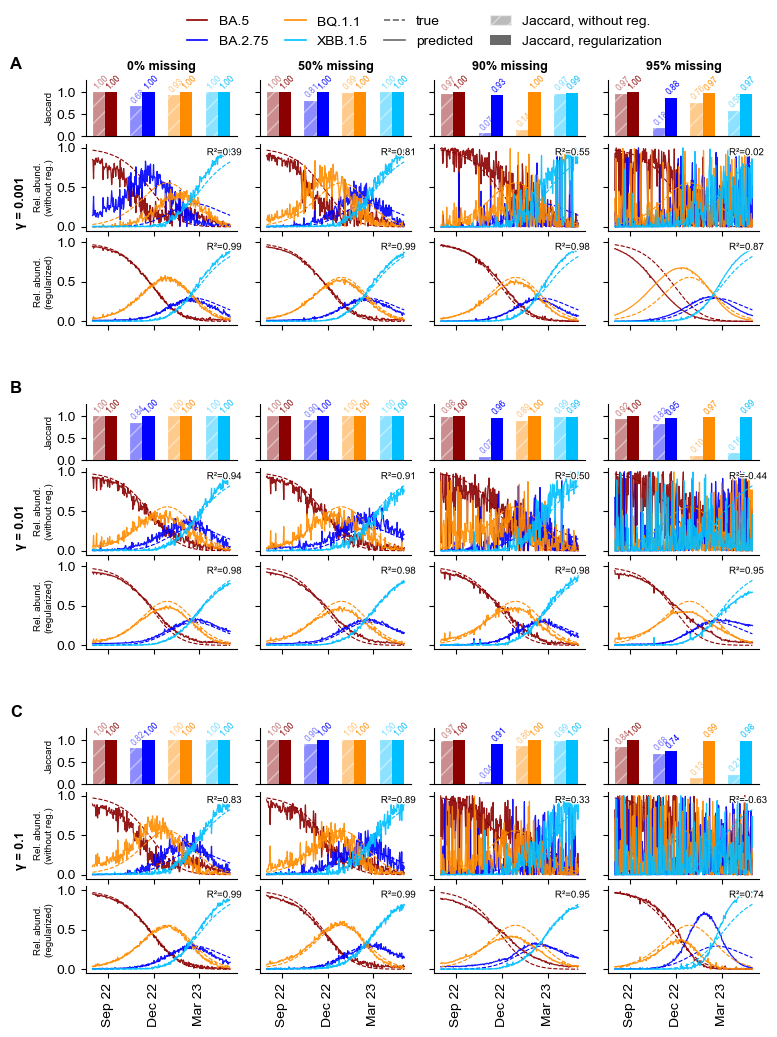

            tier  disp_level  missing_level  gamma  missing_frac  r2_10run  r2_100run  n_variants_matched_10run  n_variants_matched_100run  n_variants_total
 disp1_missing_1           1              1  0.001          0.00  0.389351   0.990547                         4                          4                 4
 disp1_missing_6           1              6  0.001          0.50  0.810492   0.990920                         4                          4                 4
disp1_missing_10           1             10  0.001          0.90  0.546145   0.976138                         4                          4                 4
disp1_missing_11           1             11  0.001          0.95  0.018808   0.868967                         4                          4                 4
 disp2_missing_1           2              1  0.010          0.00  0.939917   0.984979                         4                          4                 4
 disp2_missing_6           2              6  0.010        

In [25]:
import matplotlib.patheffects as pe

def _r_squared(true_vals, pred_vals):
    true_vals = np.asarray(true_vals, dtype=float)
    pred_vals = np.asarray(pred_vals, dtype=float)
    ss_res = np.sum((true_vals - pred_vals) ** 2)
    ss_tot = np.sum((true_vals - true_vals.mean()) ** 2)
    return np.nan if ss_tot == 0 else 1 - ss_res / ss_tot


def _jaccard_per_variant(result, df, W_covspectrum, all_vars,
                          binarize_threshold, unassigned_threshold):
    """Runs the matching pipeline for one NMF result and returns
    (jaccard_per_variant, best_component_per_variant, label_to_k, H_norm)."""
    rank = result.W.shape[1]
    W_df = pd.DataFrame(result.W, index=list(df.index),
                         columns=[f'Component_{k}' for k in range(rank)])
    W_binary = (W_df >= binarize_threshold).astype(int)

    sim_df, new_labels, best_labels = _match_components_to_ground_truth(
        W_binary, W_covspectrum, unassigned_threshold=unassigned_threshold)
    sim_df.index = new_labels
    label_to_k = {label: k for k, label in enumerate(new_labels)}

    gt_to_pred_labels = {}
    for pred_label, gt_label in zip(new_labels, best_labels):
        gt_to_pred_labels.setdefault(gt_label, []).append(pred_label)

    jaccard_per_variant, best_component_per_variant = {}, {}
    for v in all_vars:
        candidates = gt_to_pred_labels.get(v, [])
        if not candidates:
            jaccard_per_variant[v] = np.nan
            best_component_per_variant[v] = None
            continue
        scores = {pl: sim_df.loc[pl, v] for pl in candidates}
        best_pl = max(scores, key=scores.get)
        jaccard_per_variant[v] = scores[best_pl]
        best_component_per_variant[v] = best_pl

    H_norm = result.H['sim'] / result.H['sim'].sum(axis=0, keepdims=True)
    return jaccard_per_variant, best_component_per_variant, label_to_k, H_norm


def evaluate_and_plot_grid_nature(nmf_results_10, nmf_results_100, datasets,
                                   W_covspectrum, abundance_matrix,
                                   tier_config=None,
                                   binarize_threshold=0.5, unassigned_threshold=0.0,
                                   colors=None, fig_width_mm=183, cell_aspect=1.9):
    all_vars = list(W_covspectrum.columns)
    bar_colors = [colors.get(v, f'C{i}') if colors else f'C{i}' for i, v in enumerate(all_vars)]

    tier_grid = {}
    for tier in nmf_results_100:
        m = re.match(r'disp(\d+)_missing_(\d+)', tier)
        if not m:
            raise ValueError(f"Tier name '{tier}' doesn't match 'dispD_missing_M'.")
        tier_grid[(int(m.group(1)), int(m.group(2)))] = tier

    disp_levels = sorted({d for d, _ in tier_grid})
    missing_levels = sorted({mm for _, mm in tier_grid})
    n_rows, n_cols = len(disp_levels), len(missing_levels)

    row_headers = [f'disp {d}' for d in disp_levels]
    col_headers = [f'missing {mm}' for mm in missing_levels]
    gamma_by_disp, missfrac_by_col = {}, {}
    if tier_config is not None:
        cfg_by_name = {t['name']: t for t in tier_config}
        for (d, mm), name in tier_grid.items():
            cfg = cfg_by_name.get(name)
            if cfg is not None:
                gamma_by_disp[d] = cfg['gamma']
                missfrac_by_col[mm] = cfg['missing_frac']
        row_headers = [f'\u03b3 = {gamma_by_disp[d]:g}' for d in disp_levels]
        col_headers = [f'{missfrac_by_col[mm]*100:.0f}% missing' for mm in missing_levels]

    fig_w_in = fig_width_mm / 25.4
    fig_h_in = fig_w_in / n_cols * n_rows * cell_aspect
    fig = plt.figure(figsize=(fig_w_in, fig_h_in))
    outer = GridSpec(n_rows, n_cols, figure=fig,
                      left=0.06, right=0.995, top=0.92, bottom=0.05,
                      hspace=0.32, wspace=0.15)

    date_locator = mdates.MonthLocator(interval=3)
    date_formatter = mdates.DateFormatter('%b %y')
    r2_records = []
    bar_width = 0.32
    x = np.arange(len(all_vars))

    def _plot_abundance_panel(ax, dates, best_component_per_variant, label_to_k, H_norm):
        true_all, pred_all = [], []
        for i, v in enumerate(all_vars):
            ax.plot(dates, abundance_matrix[:, i], color=bar_colors[i],
                    linestyle='--', linewidth=0.8)
            best_pl = best_component_per_variant[v]
            if best_pl is not None:
                pred_vals = H_norm[label_to_k[best_pl]]
                ax.plot(dates, pred_vals, color=bar_colors[i],
                        linestyle='-', linewidth=0.9, alpha=0.9)
                true_all.append(abundance_matrix[:, i])
                pred_all.append(pred_vals)
        ax.set_ylim(-0.05, 1.05)
        ax.set_yticks([0, 0.5, 1])
        ax.spines[['top', 'right']].set_visible(False)
        r2 = np.nan
        n_matched = len(true_all)
        if true_all:
            r2 = _r_squared(np.concatenate(true_all), np.concatenate(pred_all))
            r2_text = ax.text(0.8, 0.95, f'R\u00b2={r2:.2f}', transform=ax.transAxes,
                               ha='left', va='top', fontsize=7, color='black', zorder=10)
            r2_text.set_path_effects([pe.withStroke(linewidth=2, foreground='white')])
        return r2, n_matched

    for r, disp_i in enumerate(disp_levels):
        for c, missing_j in enumerate(missing_levels):
            tier = tier_grid[(disp_i, missing_j)]
            df = datasets[tier]
            dates = pd.DatetimeIndex(df.columns)

            jacc_10, best_component_10, label_to_k_10, H_norm_10 = _jaccard_per_variant(
                nmf_results_10[tier], df, W_covspectrum, all_vars,
                binarize_threshold, unassigned_threshold)
            jacc_100, best_component_100, label_to_k_100, H_norm_100 = _jaccard_per_variant(
                nmf_results_100[tier], df, W_covspectrum, all_vars,
                binarize_threshold, unassigned_threshold)

            inner = outer[r, c].subgridspec(3, 1, height_ratios=[0.55, 0.85, 0.85], hspace=0.1)
            ax_bar = fig.add_subplot(inner[0])
            ax_ab10 = fig.add_subplot(inner[1])
            ax_ab100 = fig.add_subplot(inner[2])

            ax_bar.bar(x - bar_width / 2, [jacc_10[v] for v in all_vars],
                       width=bar_width, color=bar_colors, alpha=0.45,
                       hatch='//', edgecolor='white', linewidth=0.3)
            ax_bar.bar(x + bar_width / 2, [jacc_100[v] for v in all_vars],
                       width=bar_width, color=bar_colors, linewidth=0)
            ax_bar.set_ylim(0, 1.28)
            ax_bar.set_yticks([0, 0.5, 1])
            ax_bar.set_xticks([])
            ax_bar.spines[['top', 'right']].set_visible(False)
            if c != 0:
                ax_bar.set_yticklabels([])
            for i, v in enumerate(all_vars):
                val10 = jacc_10[v]
                if not np.isnan(val10):
                    ax_bar.text(x[i] - bar_width / 2, val10 + 0.03, f'{val10:.2f}',
                                ha='left', va='bottom', fontsize=6, color=bar_colors[i],
                                alpha=0.55, rotation=45, rotation_mode='anchor')
                val100 = jacc_100[v]
                if not np.isnan(val100):
                    ax_bar.text(x[i] + bar_width / 2, val100 + 0.03, f'{val100:.2f}',
                                ha='left', va='bottom', fontsize=6, color=bar_colors[i],
                                rotation=45, rotation_mode='anchor')

            r2_10, n_matched_10 = _plot_abundance_panel(
                ax_ab10, dates, best_component_10, label_to_k_10, H_norm_10)
            r2_100, n_matched_100 = _plot_abundance_panel(
                ax_ab100, dates, best_component_100, label_to_k_100, H_norm_100)

            ax_ab10.xaxis.set_major_locator(date_locator)
            ax_ab10.set_xticklabels([])
            ax_ab100.xaxis.set_major_locator(date_locator)
            ax_ab100.xaxis.set_major_formatter(date_formatter)
            ax_ab100.tick_params(axis='x', rotation=90)
            if r != n_rows - 1:
                ax_ab100.set_xticklabels([])
            if c != 0:
                ax_ab10.set_yticklabels([])
                ax_ab100.set_yticklabels([])

            r2_records.append(dict(
                tier=tier, disp_level=disp_i, missing_level=missing_j,
                gamma=gamma_by_disp.get(disp_i), missing_frac=missfrac_by_col.get(missing_j),
                r2_10run=r2_10, r2_100run=r2_100,
                n_variants_matched_10run=n_matched_10, n_variants_matched_100run=n_matched_100,
                n_variants_total=len(all_vars),
            ))

            if c == 0:
                ax_bar.set_ylabel('Jaccard', labelpad=2,  fontsize=7)
                ax_ab10.set_ylabel('Rel. abund.\n(without reg.)', labelpad=2, fontsize=7)
                ax_ab100.set_ylabel('Rel. abund.\n(regularized)', labelpad=2, fontsize=7)
            if r == 0:
                ax_bar.set_title(col_headers[c], fontsize=9, pad=7, fontweight='bold')

        pos = outer[r, 0].get_position(fig)
        fig.text(-0.03, pos.y0 + pos.height / 2, row_headers[r],
                  rotation=90, va='center', ha='center', fontsize=9, fontweight='bold')
        fig.text(-0.045, pos.y1 + 0.008, chr(65 + r),
                  fontsize=12, fontweight='bold', ha='left', va='bottom')


    legend_handles = (
        [plt.Line2D([0], [0], color=bar_colors[i], lw=1.2, label=v) for i, v in enumerate(all_vars)]
        + [plt.Line2D([0], [0], color='dimgray', lw=1.2, linestyle='--', label='true'),
           plt.Line2D([0], [0], color='dimgray', lw=1.2, linestyle='-', label='predicted'),
           plt.Rectangle((0, 0), 1, 1, facecolor='dimgray', alpha=0.45, hatch='//',
                          edgecolor='white', label='Jaccard, without reg.'),
           plt.Rectangle((0, 0), 1, 1, facecolor='dimgray', label='Jaccard, regularization')]
    )
    fig.legend(handles=legend_handles, loc='upper center', ncol=4,
               frameon=False, bbox_to_anchor=(0.53, 0.995), handlelength=1.5, columnspacing=1.2)

    r2_df = pd.DataFrame(r2_records)
    return fig, r2_df


fig, r2_table = evaluate_and_plot_grid_nature(
    nmf_results_unregularized, nmf_results_fitness_regularized, datasets,
    W_covspectrum=X, abundance_matrix=abundance_matrix,
    tier_config=QUALITY_TIERS, colors=colors)
fig.savefig('../results/simulated_data/fig_nmf_grid_simulation_2_fitness.pdf', bbox_inches='tight')
plt.show()

print(r2_table.to_string(index=False))
#r2_table.to_csv('r2_estimates_per_tier.csv', index=False)

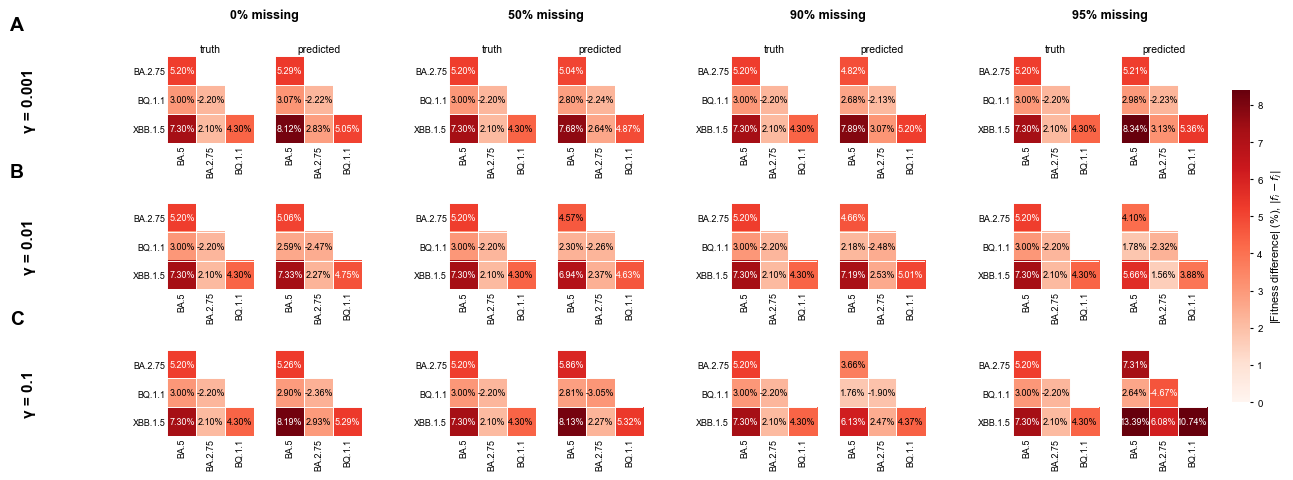

In [26]:
variants   = ['BA.2.75', 'BQ.1.1', 'XBB.1.5']
f_arr = [-0.0,  0.052, 0.03, 0.073]

true_fitness={
    'BA.5': 0.0,
    'BA.2.75': 0.052,
    'BQ.1.1': 0.03,
    'XBB.1.5': 0.073
}

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

def _lower_tri_submatrix(mat):
    """Trims an (n, n) antisymmetric matrix to its (n-1, n-1) strict lower
    triangle: drops row 0 and the last column (always empty), blanks the
    remaining upper-triangle cells with NaN."""
    n = mat.shape[0]
    sub = mat[1:, :-1].copy()
    n_sub = n - 1
    upper_mask = np.triu(np.ones((n_sub, n_sub), dtype=bool), k=1)
    sub[upper_mask] = np.nan
    return sub


def plot_fitness_diff_heatmaps_grid(nmf_results_100, datasets, W_covspectrum, true_fitness,
                                     tier_config=None, binarize_threshold=0.5, unassigned_threshold=0.00,
                                     fig_width_mm=320, cell_aspect=0.55, cmap='Reds', annot_fontsize=6.5,
                                     col_gap=0.45, row_gap=0.2, tick_fontsize=6.5, title_fontsize=7.5,
                                     col_hdr_fontsize=9, row_hdr_fontsize=11, panel_fontsize=14,
                                     cb_label_fontsize=8, cb_tick_fontsize=7):
    all_vars = list(W_covspectrum.columns)
    n_vars = len(all_vars)
    n_sub = n_vars - 1
    labels_y = all_vars[1:]
    labels_x = all_vars[:-1]

    cmap_obj = plt.get_cmap(cmap).copy()
    cmap_obj.set_bad('white')

    true_vec = np.array([true_fitness.get(v, np.nan) for v in all_vars]) * 100
    true_mat = true_vec[:, None] - true_vec[None, :]
    true_sub = _lower_tri_submatrix(true_mat)

    tier_grid = {}
    for tier in nmf_results_100:
        m = re.match(r'disp(\d+)_missing_(\d+)', tier)
        if not m:
            raise ValueError(f"Tier name '{tier}' doesn't match 'dispD_missing_M'.")
        tier_grid[(int(m.group(1)), int(m.group(2)))] = tier

    disp_levels = sorted({d for d, _ in tier_grid})
    missing_levels = sorted({mm for _, mm in tier_grid})
    n_rows, n_cols = len(disp_levels), len(missing_levels)

    row_headers = [f'disp {d}' for d in disp_levels]
    col_headers = [f'missing {mm}' for mm in missing_levels]
    gamma_by_disp, missfrac_by_col = {}, {}
    if tier_config is not None:
        cfg_by_name = {t['name']: t for t in tier_config}
        for (d, mm), name in tier_grid.items():
            cfg = cfg_by_name.get(name)
            if cfg is not None:
                gamma_by_disp[d] = cfg['gamma']
                missfrac_by_col[mm] = cfg['missing_frac']
        row_headers = [f'\u03b3 = {gamma_by_disp[d]:g}' for d in disp_levels]
        col_headers = [f'{missfrac_by_col[mm]*100:.0f}% missing' for mm in missing_levels]

    all_true_abs = np.nanmax(np.abs(true_sub))
    vlim = all_true_abs * 1.15 if all_true_abs > 0 else 1.0

    fig_w_in = fig_width_mm / 25.4
    fig_h_in = fig_w_in / n_cols * n_rows * cell_aspect
    fig = plt.figure(figsize=(fig_w_in, fig_h_in))
    outer = GridSpec(n_rows, n_cols, figure=fig,
                      left=0.075, right=0.90, top=0.85, bottom=0.05,
                      hspace=row_gap, wspace=col_gap)

    im = None
    for r, disp_i in enumerate(disp_levels):
        for c, missing_j in enumerate(missing_levels):
            tier = tier_grid[(disp_i, missing_j)]
            df = datasets[tier]
            fit_100 = _fitness_per_variant_from_result(
                nmf_results_100[tier], df, W_covspectrum, all_vars,
                binarize_threshold, unassigned_threshold)
            pred_vec = np.array([fit_100[v] for v in all_vars]) * 100
            pred_mat = pred_vec[:, None] - pred_vec[None, :]
            pred_sub = _lower_tri_submatrix(pred_mat)

            inner = outer[r, c].subgridspec(1, 2, wspace=0.25)
            ax_true = fig.add_subplot(inner[0])
            ax_pred = fig.add_subplot(inner[1])

            im = ax_true.imshow(np.abs(true_sub), cmap=cmap_obj, vmin=0, vmax=vlim, aspect='equal')
            ax_pred.imshow(np.abs(pred_sub), cmap=cmap_obj, vmin=0, vmax=vlim, aspect='equal')

            for ax, mat, show_ylabels in [(ax_true, true_sub, True), (ax_pred, pred_sub, False)]:
                ax.set_xticks(range(n_sub)); ax.set_yticks(range(n_sub))
                ax.set_xticklabels(labels_x, fontsize=tick_fontsize, rotation=90)
                ax.set_yticklabels(labels_y if show_ylabels else [], fontsize=tick_fontsize)
                ax.tick_params(length=0, pad=1.5)
                ax.set_xticks(np.arange(-.5, n_sub, 1), minor=True)
                ax.set_yticks(np.arange(-.5, n_sub, 1), minor=True)
                ax.grid(which='minor', color='white', linewidth=0.7)
                ax.tick_params(which='minor', length=0)
                for i in range(n_sub):
                    for j in range(n_sub):
                        val = mat[i, j]
                        if not np.isnan(val):
                            txt_color = 'white' if abs(val) > vlim * 0.55 else 'black'
                            ax.text(j, i, f'{val:.2f}%', ha='center', va='center',
                                    fontsize=annot_fontsize, color=txt_color)
                for spine in ax.spines.values():
                    spine.set_visible(False)

            if r == 0:
                ax_true.set_title('truth', fontsize=title_fontsize, pad=3)
                ax_pred.set_title('predicted', fontsize=title_fontsize, pad=3)
                mid_x = (ax_true.get_position().x0 + ax_pred.get_position().x1) / 2
                fig.text(mid_x, outer[r, c].get_position(fig).y1 + 0.038, col_headers[c],
                          ha='center', fontsize=col_hdr_fontsize, fontweight='bold')

        pos = outer[r, 0].get_position(fig)
        fig.text(-0.035, pos.y0 + pos.height / 2, row_headers[r],
                  rotation=90, va='center', ha='center', fontsize=row_hdr_fontsize, fontweight='bold')
        fig.text(-0.05, pos.y1 + 0.008, chr(65 + r),
                  fontsize=panel_fontsize, fontweight='bold', ha='left', va='bottom')

    cax = fig.add_axes([0.92, 0.15, 0.014, 0.6])
    cb = fig.colorbar(im, cax=cax)
    cb.set_label('|Fitness difference| (%), $|f_i - f_j|$', fontsize=cb_label_fontsize)
    cb.ax.tick_params(labelsize=cb_tick_fontsize, length=2)
    cb.outline.set_visible(False)

    return fig



fig = plot_fitness_diff_heatmaps_grid(
    nmf_results_fitness_regularized, datasets, W_covspectrum=X, true_fitness=true_fitness,
    tier_config=QUALITY_TIERS)
fig.savefig('../results/simulated_data/fig_fitness_diff_heatmaps_grid_period2.pdf', bbox_inches='tight')
plt.show()

                tier  disp  missing_frac  gamma reference_variant  \
0    disp1_missing_1     1          0.00  0.001              BA.5   
1    disp1_missing_6     1          0.50  0.001              BA.5   
2   disp1_missing_10     1          0.90  0.001              BA.5   
3   disp1_missing_11     1          0.95  0.001              BA.5   
4    disp2_missing_1     2          0.00  0.010              BA.5   
5    disp2_missing_6     2          0.50  0.010              BA.5   
6   disp2_missing_10     2          0.90  0.010              BA.5   
7   disp2_missing_11     2          0.95  0.010              BA.5   
8    disp3_missing_1     3          0.00  0.100              BA.5   
9    disp3_missing_6     3          0.50  0.100              BA.5   
10  disp3_missing_10     3          0.90  0.100              BA.5   
11  disp3_missing_11     3          0.95  0.100              BA.5   

    generation_time    mae_pct  
0                 7   3.758200  
1                 7   2.579991  
2  

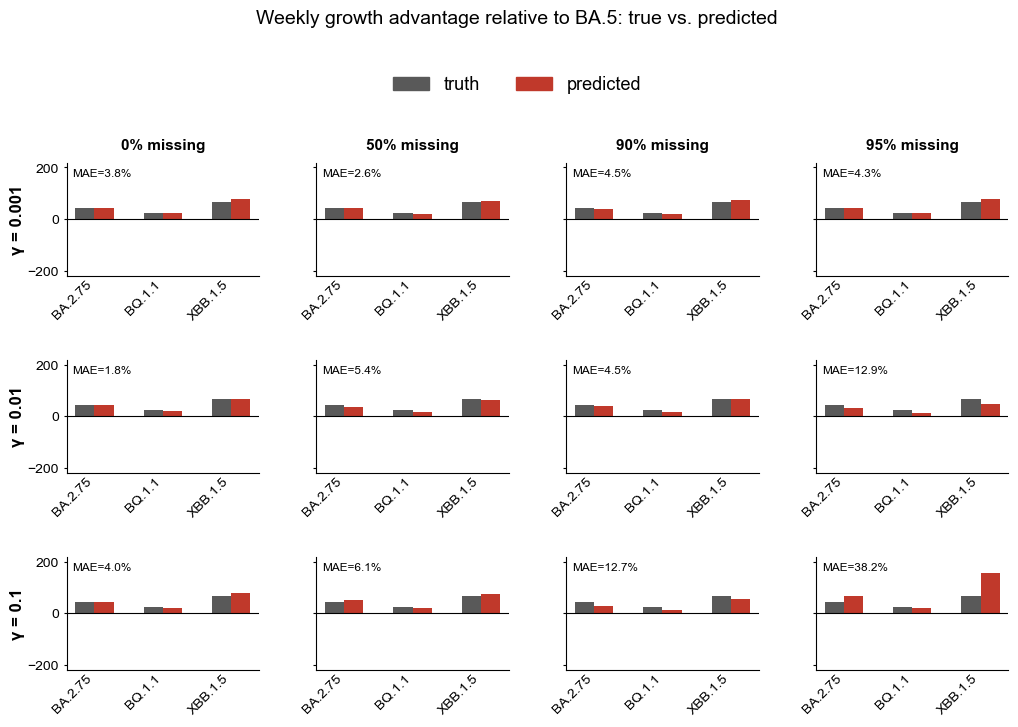

In [27]:
def plot_growth_advantage_bars_grid(nmf_results_100, datasets, W_covspectrum, true_fitness,
                                     reference_variant=None, tier_config=None,
                                     generation_time=1.0,
                                     binarize_threshold=0.5, unassigned_threshold=0.01,
                                     fig_width_mm=260, cell_aspect=1.0,
                                     true_color='0.35', pred_color='#c0392b',
                                     bar_width=0.28,
                                     title_fontsize=11, tick_fontsize=10,
                                     row_header_fontsize=12, suptitle_fontsize=14,
                                     legend_fontsize=13, err_fontsize=8.5):
    """Grid of grouped bar charts comparing true vs. predicted GROWTH ADVANTAGE,
    100*(exp(generation_time*(f_i-f_ref))-1), each expressed relative to a
    single reference variant, across the (gamma x missing_frac) tier grid.
    Each panel is annotated with its own MAE = mean(|pred_adv - true_adv|),
    in percentage points, and a tidy summary_df of per-tier MAE is returned
    alongside the figure. Font sizes are all exposed as parameters so the
    figure can be scaled up for readability without editing the function body."""
    all_vars = list(W_covspectrum.columns)
    if reference_variant is None:
        reference_variant = all_vars[0]
    other_vars = [v for v in all_vars if v != reference_variant]
    n_sub = len(other_vars)
    x = np.arange(n_sub)

    true_ref = true_fitness[reference_variant]
    true_log_diffs = np.array([true_fitness[v] - true_ref for v in other_vars])
    true_adv = 100 * (np.exp(generation_time * true_log_diffs) - 1)

    tier_grid = {}
    for tier in nmf_results_100:
        m = re.match(r'disp(\d+)_missing_(\d+)', tier)
        if not m:
            raise ValueError(f"Tier name '{tier}' doesn't match 'dispD_missing_M'.")
        tier_grid[(int(m.group(1)), int(m.group(2)))] = tier

    disp_levels = sorted({d for d, _ in tier_grid})
    missing_levels = sorted({mm for _, mm in tier_grid})
    n_rows, n_cols = len(disp_levels), len(missing_levels)

    row_headers = [f'disp {d}' for d in disp_levels]
    col_headers = [f'missing {mm}' for mm in missing_levels]
    gamma_by_disp, missfrac_by_col = {}, {}
    if tier_config is not None:
        cfg_by_name = {t['name']: t for t in tier_config}
        for (d, mm), name in tier_grid.items():
            cfg = cfg_by_name.get(name)
            if cfg is not None:
                gamma_by_disp[d] = cfg['gamma']
                missfrac_by_col[mm] = cfg['missing_frac']
        row_headers = [f'\u03b3 = {gamma_by_disp[d]:g}' for d in disp_levels]
        col_headers = [f'{missfrac_by_col[mm]*100:.0f}% missing' for mm in missing_levels]

    pred_adv_by_tier = {}
    for (d, mm), tier in tier_grid.items():
        df = datasets[tier]
        fit_100 = _fitness_per_variant_from_result(
            nmf_results_100[tier], df, W_covspectrum, all_vars,
            binarize_threshold, unassigned_threshold)
        pred_log_diffs = np.array([fit_100[v] - fit_100[reference_variant] for v in other_vars])
        pred_adv_by_tier[tier] = 100 * (np.exp(generation_time * pred_log_diffs) - 1)

    all_vals = np.concatenate([true_adv] + list(pred_adv_by_tier.values()))
    vlim = np.nanmax(np.abs(all_vals)) * 1.4 if np.nanmax(np.abs(all_vals)) > 0 else 1.0

    fig_w_in = fig_width_mm / 25.4
    fig_h_in = fig_w_in / n_cols * n_rows * cell_aspect
    fig = plt.figure(figsize=(fig_w_in, fig_h_in))
    outer = GridSpec(n_rows, n_cols, figure=fig,
                      left=0.06, right=0.98, top=0.82, bottom=0.16,
                      hspace=0.75, wspace=0.3)

    summary = []

    for r, disp_i in enumerate(disp_levels):
        for c, missing_j in enumerate(missing_levels):
            tier = tier_grid[(disp_i, missing_j)]
            pred_adv = pred_adv_by_tier[tier]
            mae_tier = np.mean(np.abs(pred_adv - true_adv))
            summary.append({
                'tier': tier, 'disp': disp_i,
                'missing_frac': missfrac_by_col.get(missing_j, missing_j),
                'gamma': gamma_by_disp.get(disp_i, np.nan),
                'reference_variant': reference_variant,
                'generation_time': generation_time,
                'mae_pct': mae_tier,
            })

            ax = fig.add_subplot(outer[r, c])
            ax.bar(x - bar_width / 2, true_adv, bar_width, color=true_color, label='truth')
            ax.bar(x + bar_width / 2, pred_adv, bar_width, color=pred_color, label='predicted')
            ax.axhline(0, color='black', linewidth=0.8)
            ax.set_ylim(-vlim, vlim)
            ax.set_xticks(x)
            ax.set_xticklabels(other_vars, fontsize=tick_fontsize, rotation=45, ha='right')
            ax.tick_params(axis='y', labelsize=tick_fontsize, length=2)
            ax.tick_params(axis='x', length=0, pad=2)
            if c != 0:
                ax.set_yticklabels([])
            for spine in ['top', 'right']:
                ax.spines[spine].set_visible(False)

            ax.text(0.03, 0.95, f'MAE={mae_tier:.1f}%', transform=ax.transAxes,
                     ha='left', va='top', fontsize=err_fontsize, color='black')

            if r == 0:
                ax.set_title(col_headers[c], fontsize=title_fontsize, fontweight='bold', pad=10)

        pos = outer[r, 0].get_position(fig)
        fig.text(0.012, pos.y0 + pos.height / 2, row_headers[r],
                  rotation=90, va='center', ha='center', fontsize=row_header_fontsize,
                  fontweight='bold')

    fig.suptitle(f'Weekly growth advantage relative to {reference_variant}: '
                 f'true vs. predicted',
                 fontsize=suptitle_fontsize, y=1.02)

    handles = [plt.Rectangle((0, 0), 1, 1, color=true_color), plt.Rectangle((0, 0), 1, 1, color=pred_color)]
    fig.legend(handles, ['truth', 'predicted'], loc='upper center', bbox_to_anchor=(0.5, 0.955),
               ncol=2, fontsize=legend_fontsize, frameon=False)

    summary_df = pd.DataFrame(summary)
    return summary_df, fig


summary_df, fig = plot_growth_advantage_bars_grid(
    nmf_results_fitness_regularized, datasets, W_covspectrum=X, true_fitness=true_fitness,
    tier_config=QUALITY_TIERS, reference_variant='BA.5', generation_time=7)

fig.savefig('../results/simulated_data/fig_growth_advantage_bars_grid_2.pdf', bbox_inches='tight')
print(summary_df)
plt.show()

# Suboptimal number of variants

# One variant less than the ground truth

In [28]:
TARGET_MISSING_FRACS = {0.0, 0.5, 0.9, 0.95}
RANK = 3                                           # too few variants (Omicron)

selected_tiers  = {t['name'] for t in QUALITY_TIERS if t['missing_frac'] in TARGET_MISSING_FRACS}
datasets_subset = {tier: df for tier, df in datasets.items() if tier in selected_tiers}

#cv_key = lambda tier: tier                         # tier name -> 'location' name in simulated_data_cv
cv_key = lambda tier: f"{tier}_omicron_replicator"

# CV-optimal lambdas at rank 4 for every tier
cv = simulated_data_cv.dropna(subset=['mean_error'])
cv = cv[cv['n_variants'] == RANK]
opt_lambdas = {}
for tier in datasets_subset:
    g = cv[cv['location'] == cv_key(tier)]
    if g.empty:
        raise KeyError(f"no CV results at rank {RANK} for '{cv_key(tier)}' -- check cv_key / names")
    b = g.loc[g['mean_error'].idxmin()]
    opt_lambdas[tier] = dict(lambda_w=float(b['lambda_w']), lambda_h=float(b['lambda_h']),
                             lambda_f=float(b['lambda_f']))
    print(f"{tier}: lambda_w={b['lambda_w']:g}, lambda_h={b['lambda_h']:g}, lambda_f={b['lambda_f']:g}"
          f"  (CV error {b['mean_error']:.4g})")

NMF_KWARGS_base = dict(
    masking_option=0, rank=RANK, rel_tol=1e-4, bandwidth=10.0, n_run=10,
    random_state=42, n_jobs=-1, n_mu_steps=1)

nmf_results_fitness_regularized = {}
for tier, df in datasets_subset.items():
    print(f"Running joint_soft_dynamics_nmf (CV-optimal) for tier '{tier}'...")
    nmf_results_fitness_regularized[tier] = joint_soft_dynamics_nmf(
        {'sim': df}, **NMF_KWARGS_base, **opt_lambdas[tier])

nmf_results_unregularized = {}
for tier, df in datasets_subset.items():
    print(f"Running joint_soft_dynamics_nmf (unregularized) for tier '{tier}'...")
    nmf_results_unregularized[tier] = joint_soft_dynamics_nmf(
        {'sim': df}, **NMF_KWARGS_base, lambda_w=0, lambda_h=0, lambda_f=0)

disp1_missing_1: lambda_w=0.01, lambda_h=30, lambda_f=0  (CV error 0.00781)
disp1_missing_6: lambda_w=0.001, lambda_h=20, lambda_f=0  (CV error 0.007552)
disp1_missing_10: lambda_w=1, lambda_h=0.5, lambda_f=7  (CV error 0.008332)
disp1_missing_11: lambda_w=0.1, lambda_h=0.01, lambda_f=10  (CV error 0.01105)
disp2_missing_1: lambda_w=0.2, lambda_h=20, lambda_f=0.2  (CV error 0.008763)
disp2_missing_6: lambda_w=0.01, lambda_h=8, lambda_f=0.4  (CV error 0.009178)
disp2_missing_10: lambda_w=0.9, lambda_h=0.1, lambda_f=9  (CV error 0.009961)
disp2_missing_11: lambda_w=0.5, lambda_h=0.1, lambda_f=9  (CV error 0.009953)
disp3_missing_1: lambda_w=0.5, lambda_h=30, lambda_f=0  (CV error 0.01295)
disp3_missing_6: lambda_w=3, lambda_h=20, lambda_f=0.1  (CV error 0.01298)
disp3_missing_10: lambda_w=0.7, lambda_h=0.4, lambda_f=20  (CV error 0.01437)
disp3_missing_11: lambda_w=0.3, lambda_h=0.001, lambda_f=7  (CV error 0.01637)
Running joint_soft_dynamics_nmf (CV-optimal) for tier 'disp1_missing_1'.

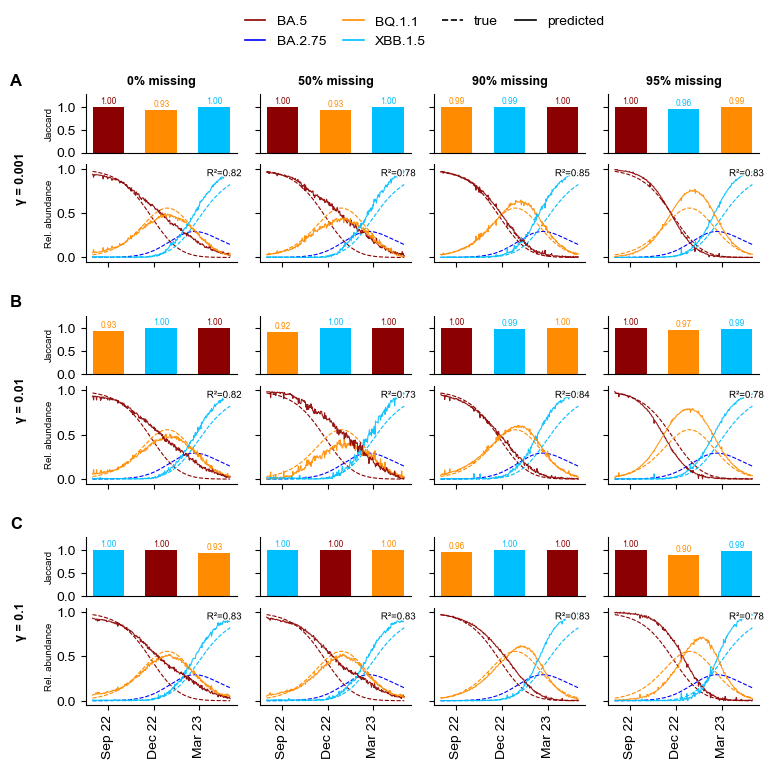

            tier  disp_level  missing_level  gamma  missing_frac       r2  n_variants_matched  n_variants_total  n_components  jaccard_all_components_mean  jaccard_all_components_min
 disp1_missing_1           1              1  0.001          0.00 0.820683                   3                 4             3                     0.977778                    0.933333
 disp1_missing_6           1              6  0.001          0.50 0.782432                   3                 4             3                     0.977778                    0.933333
disp1_missing_10           1             10  0.001          0.90 0.849525                   3                 4             3                     0.991910                    0.986842
disp1_missing_11           1             11  0.001          0.95 0.826160                   3                 4             3                     0.980799                    0.955556
 disp2_missing_1           2              1  0.010          0.00 0.820877            

In [29]:
def _r_squared(true_vals, pred_vals):
    true_vals = np.asarray(true_vals, dtype=float)
    pred_vals = np.asarray(pred_vals, dtype=float)
    ss_res = np.sum((true_vals - pred_vals) ** 2)
    ss_tot = np.sum((true_vals - true_vals.mean()) ** 2)
    return np.nan if ss_tot == 0 else 1 - ss_res / ss_tot


def _match_components_to_ground_truth_suboptimal(W_binary, W_covspectrum):
    """Every fitted component is assigned to whichever ground-truth variant
    it is most Jaccard-similar to (argmax) -- unconditionally. Multiple
    components can land on the same variant (many-to-one); there is no
    'unassigned' category."""
    all_muts = sorted(set(W_binary.index) | set(W_covspectrum.index))
    W_pred_final = W_binary.reindex(all_muts, fill_value=0)
    W_true_final = W_covspectrum.reindex(all_muts, fill_value=0)

    dist_matrix = cdist(W_pred_final.values.T, W_true_final.values.T, metric='jaccard')
    sim_matrix = 1 - dist_matrix

    sim_df = pd.DataFrame(sim_matrix, index=W_binary.columns, columns=W_covspectrum.columns)
    sim_df = sim_df.fillna(0.0)

    best_idx = sim_df.values.argmax(axis=1)
    best_labels = [sim_df.columns[i] for i in best_idx]

    counts = {}
    new_labels = []
    for lbl in best_labels:
        counts[lbl] = counts.get(lbl, 0) + 1
        new_labels.append(lbl if counts[lbl] == 1 else f"{lbl} ({counts[lbl]})")

    return sim_df, new_labels, best_labels


def _jaccard_per_variant(result, df, W_covspectrum, all_vars, binarize_threshold):
    """Runs the matching pipeline for one NMF result and returns
    (jaccard_per_variant, best_component_per_variant, label_to_k, H_norm,
     best_labels, jaccard_per_component).

    jaccard_per_variant / best_component_per_variant: per known ground-truth
    variant, the best-matching component's Jaccard score / label.

    best_labels / jaccard_per_component: per FITTED COMPONENT (in order
    Component_0..Component_{rank-1}), the matched ground-truth variant name
    and that component's own Jaccard similarity to it. Every component is
    matched to something -- see _match_components_to_ground_truth_suboptimal.
    """
    rank = result.W.shape[1]
    W_df = pd.DataFrame(result.W, index=list(df.index),
                         columns=[f'Component_{k}' for k in range(rank)])
    W_binary = (W_df >= binarize_threshold).astype(int)

    sim_df, new_labels, best_labels = _match_components_to_ground_truth_suboptimal(W_binary, W_covspectrum)
    jaccard_per_component = sim_df.max(axis=1).values  # one score per component, in component order
    sim_df.index = new_labels
    label_to_k = {label: k for k, label in enumerate(new_labels)}

    gt_to_pred_labels = {}
    for pred_label, gt_label in zip(new_labels, best_labels):
        gt_to_pred_labels.setdefault(gt_label, []).append(pred_label)

    jaccard_per_variant, best_component_per_variant = {}, {}
    for v in all_vars:
        candidates = gt_to_pred_labels.get(v, [])
        if not candidates:
            jaccard_per_variant[v] = np.nan
            best_component_per_variant[v] = None
            continue
        scores = {pl: sim_df.loc[pl, v] for pl in candidates}
        best_pl = max(scores, key=scores.get)
        jaccard_per_variant[v] = scores[best_pl]
        best_component_per_variant[v] = best_pl

    H_norm = result.H['sim'] / result.H['sim'].sum(axis=0, keepdims=True)
    return (jaccard_per_variant, best_component_per_variant, label_to_k, H_norm,
            best_labels, jaccard_per_component)


def evaluate_and_plot_grid_nature(nmf_results, datasets,
                                   W_covspectrum, abundance_matrix,
                                   tier_config=None,
                                   binarize_threshold=0.5,
                                   colors=None, fig_width_mm=183, cell_aspect=1.3):
    """Regularized-only version: one Jaccard-bar panel + one abundance panel
    per grid cell (no unregularized comparison)."""
    all_vars = list(W_covspectrum.columns)
    bar_colors = [colors.get(v, f'C{i}') if colors else f'C{i}' for i, v in enumerate(all_vars)]

    tier_grid = {}
    for tier in nmf_results:
        m = re.match(r'disp(\d+)_missing_(\d+)', tier)
        if not m:
            raise ValueError(f"Tier name '{tier}' doesn't match 'dispD_missing_M'.")
        tier_grid[(int(m.group(1)), int(m.group(2)))] = tier

    disp_levels = sorted({d for d, _ in tier_grid})
    missing_levels = sorted({mm for _, mm in tier_grid})
    n_rows, n_cols = len(disp_levels), len(missing_levels)

    row_headers = [f'disp {d}' for d in disp_levels]
    col_headers = [f'missing {mm}' for mm in missing_levels]
    gamma_by_disp, missfrac_by_col = {}, {}
    if tier_config is not None:
        cfg_by_name = {t['name']: t for t in tier_config}
        for (d, mm), name in tier_grid.items():
            cfg = cfg_by_name.get(name)
            if cfg is not None:
                gamma_by_disp[d] = cfg['gamma']
                missfrac_by_col[mm] = cfg['missing_frac']
        row_headers = [f'\u03b3 = {gamma_by_disp[d]:g}' for d in disp_levels]
        col_headers = [f'{missfrac_by_col[mm]*100:.0f}% missing' for mm in missing_levels]

    fig_w_in = fig_width_mm / 25.4
    fig_h_in = fig_w_in / n_cols * n_rows * cell_aspect
    fig = plt.figure(figsize=(fig_w_in, fig_h_in))
    outer = GridSpec(n_rows, n_cols, figure=fig,
                      left=0.06, right=0.995, top=0.92, bottom=0.05,
                      hspace=0.32, wspace=0.15)

    date_locator = mdates.MonthLocator(interval=3)
    date_formatter = mdates.DateFormatter('%b %y')
    r2_records = []
    bar_width = 0.6

    def _component_colors(best_labels):
        """One color per component, taken directly from the ground-truth
        palette -- the color of whichever variant it matched."""
        return [bar_colors[all_vars.index(v)] for v in best_labels]

    def _plot_abundance_panel(ax, dates, best_component_per_variant, label_to_k, H_norm,
                            component_colors):
        true_all, pred_all = [], []
        for i, v in enumerate(all_vars):
            ax.plot(dates, abundance_matrix[:, i], color=bar_colors[i],
                    linestyle='--', linewidth=0.8)

        rank = H_norm.shape[0]
        for k in range(rank):
            ax.plot(dates, H_norm[k], color=component_colors[k], linestyle='-', linewidth=0.8, alpha=0.9)

        n_matched = 0
        for i, v in enumerate(all_vars):
            best_pl = best_component_per_variant[v]
            true_all.append(abundance_matrix[:, i])
            if best_pl is not None:
                pred_all.append(H_norm[label_to_k[best_pl]])
                n_matched += 1
            else:
                # no component was assigned to this variant -- score it as a
                # predicted abundance of 0 everywhere, rather than dropping it
                pred_all.append(np.zeros_like(abundance_matrix[:, i]))

        ax.set_ylim(-0.05, 1.05)
        ax.set_yticks([0, 0.5, 1])
        ax.spines[['top', 'right']].set_visible(False)
        r2 = np.nan
        if true_all:
            r2 = _r_squared(np.concatenate(true_all), np.concatenate(pred_all))
            r2_text = ax.text(0.8, 0.95, f'R\u00b2={r2:.2f}', transform=ax.transAxes,
                            ha='left', va='top', fontsize=7, color='black', zorder=10)
            r2_text.set_path_effects([pe.withStroke(linewidth=2, foreground='white')])
        return r2, n_matched
    

    
    for r, disp_i in enumerate(disp_levels):
        for c, missing_j in enumerate(missing_levels):
            tier = tier_grid[(disp_i, missing_j)]
            df = datasets[tier]
            dates = pd.DatetimeIndex(df.columns)

            (jacc, best_component, label_to_k, H_norm,
             best_labels, jaccard_per_component) = _jaccard_per_variant(
                nmf_results[tier], df, W_covspectrum, all_vars, binarize_threshold)

            comp_colors = _component_colors(best_labels)

            inner = outer[r, c].subgridspec(2, 1, height_ratios=[0.6, 1.0], hspace=0.15)
            ax_bar = fig.add_subplot(inner[0])
            ax_ab = fig.add_subplot(inner[1])

            # ── Jaccard bars: one bar per fitted component ──
            rank = len(best_labels)
            xk = np.arange(rank)
            ax_bar.bar(xk, jaccard_per_component, width=bar_width, color=comp_colors)
            ax_bar.set_ylim(0, 1.28)
            ax_bar.set_yticks([0, 0.5, 1])
            ax_bar.set_xticks([])
            ax_bar.spines[['top', 'right']].set_visible(False)
            if c != 0:
                ax_bar.set_yticklabels([])
            for k in range(rank):
                val = jaccard_per_component[k]
                if not np.isnan(val):
                    ax_bar.text(xk[k], val + 0.03, f'{val:.2f}',
                                ha='center', va='bottom', fontsize=6, color=comp_colors[k])

            r2, n_matched = _plot_abundance_panel(
                ax_ab, dates, best_component, label_to_k, H_norm, comp_colors)

            ax_ab.xaxis.set_major_locator(date_locator)
            ax_ab.xaxis.set_major_formatter(date_formatter)
            ax_ab.tick_params(axis='x', rotation=90)
            if r != n_rows - 1:
                ax_ab.set_xticklabels([])
            if c != 0:
                ax_ab.set_yticklabels([])

            r2_records.append(dict(
                tier=tier, disp_level=disp_i, missing_level=missing_j,
                gamma=gamma_by_disp.get(disp_i), missing_frac=missfrac_by_col.get(missing_j),
                r2=r2, n_variants_matched=n_matched, n_variants_total=len(all_vars),
                n_components=rank,
                jaccard_all_components_mean=np.nanmean(jaccard_per_component),
                jaccard_all_components_min=np.nanmin(jaccard_per_component),
            ))

            if c == 0:
                ax_bar.set_ylabel('Jaccard', labelpad=2, fontsize=7)
                ax_ab.set_ylabel('Rel. abundance', labelpad=2, fontsize=7)
            if r == 0:
                ax_bar.set_title(col_headers[c], fontsize=9, pad=7, fontweight='bold')
        pos = outer[r, 0].get_position(fig)
        fig.text(-0.03, pos.y0 + pos.height / 2, row_headers[r],
                  rotation=90, va='center', ha='center', fontsize=9, fontweight='bold')
        fig.text(-0.045, pos.y1 + 0.008, chr(65 + r),
                  fontsize=12, fontweight='bold', ha='left', va='bottom')

    legend_handles = (
        [plt.Line2D([0], [0], color=bar_colors[i], lw=1.2, label=v) for i, v in enumerate(all_vars)]
        + [plt.Line2D([0], [0], color='black', lw=1.2, linestyle='--', label='true'),
           plt.Line2D([0], [0], color='black', lw=1.2, linestyle='-', label='predicted')]
    )
    fig.legend(handles=legend_handles, loc='upper center', ncol=4,
               frameon=False, bbox_to_anchor=(0.53, 1.05), handlelength=1.5, columnspacing=1.2)

    r2_df = pd.DataFrame(r2_records)
    return fig, r2_df


fig, r2_table = evaluate_and_plot_grid_nature(
    nmf_results_fitness_regularized, datasets,
    W_covspectrum=X, abundance_matrix=abundance_matrix,
    tier_config=QUALITY_TIERS, colors=colors)
fig.savefig('../results/simulated_data/fig_nmf_grid_simulation_2_fitness_3_variants.pdf', bbox_inches='tight')

plt.show()

print(r2_table.to_string(index=False))
#r2_table.to_csv('r2_estimates_per_tier.csv', index=False)

# One variant too many

In [30]:
TARGET_MISSING_FRACS = {0.0, 0.5, 0.9, 0.95}
RANK = 5                                           # too many variants (Omicron)

selected_tiers  = {t['name'] for t in QUALITY_TIERS if t['missing_frac'] in TARGET_MISSING_FRACS}
datasets_subset = {tier: df for tier, df in datasets.items() if tier in selected_tiers}

#cv_key = lambda tier: tier                         # tier name -> 'location' name in simulated_data_cv
cv_key = lambda tier: f"{tier}_omicron_replicator"

# CV-optimal lambdas at rank 4 for every tier
cv = simulated_data_cv.dropna(subset=['mean_error'])
cv = cv[cv['n_variants'] == RANK]
opt_lambdas = {}
for tier in datasets_subset:
    g = cv[cv['location'] == cv_key(tier)]
    if g.empty:
        raise KeyError(f"no CV results at rank {RANK} for '{cv_key(tier)}' -- check cv_key / names")
    b = g.loc[g['mean_error'].idxmin()]
    opt_lambdas[tier] = dict(lambda_w=float(b['lambda_w']), lambda_h=float(b['lambda_h']),
                             lambda_f=float(b['lambda_f']))
    print(f"{tier}: lambda_w={b['lambda_w']:g}, lambda_h={b['lambda_h']:g}, lambda_f={b['lambda_f']:g}"
          f"  (CV error {b['mean_error']:.4g})")

NMF_KWARGS_base = dict(
    masking_option=0, rank=RANK, rel_tol=1e-4, bandwidth=10.0, n_run=10,
    random_state=42, n_jobs=-1, n_mu_steps=1)

nmf_results_fitness_regularized = {}
for tier, df in datasets_subset.items():
    print(f"Running joint_soft_dynamics_nmf (CV-optimal) for tier '{tier}'...")
    nmf_results_fitness_regularized[tier] = joint_soft_dynamics_nmf(
        {'sim': df}, **NMF_KWARGS_base, **opt_lambdas[tier])

nmf_results_unregularized = {}
for tier, df in datasets_subset.items():
    print(f"Running joint_soft_dynamics_nmf (unregularized) for tier '{tier}'...")
    nmf_results_unregularized[tier] = joint_soft_dynamics_nmf(
        {'sim': df}, **NMF_KWARGS_base, lambda_w=0, lambda_h=0, lambda_f=0)

disp1_missing_1: lambda_w=6, lambda_h=20, lambda_f=9  (CV error 0.007294)
disp1_missing_6: lambda_w=2, lambda_h=20, lambda_f=4  (CV error 0.007036)
disp1_missing_10: lambda_w=0.6, lambda_h=7, lambda_f=2  (CV error 0.008136)
disp1_missing_11: lambda_w=0.001, lambda_h=20, lambda_f=0  (CV error 0.01112)
disp2_missing_1: lambda_w=9, lambda_h=0, lambda_f=50  (CV error 0.008317)
disp2_missing_6: lambda_w=3, lambda_h=8, lambda_f=8  (CV error 0.008673)
disp2_missing_10: lambda_w=0.4, lambda_h=20, lambda_f=0.5  (CV error 0.009502)
disp2_missing_11: lambda_w=0.001, lambda_h=20, lambda_f=0.001  (CV error 0.009848)
disp3_missing_1: lambda_w=5, lambda_h=50, lambda_f=4  (CV error 0.01243)
disp3_missing_6: lambda_w=3, lambda_h=30, lambda_f=2  (CV error 0.01233)
disp3_missing_10: lambda_w=0.4, lambda_h=7, lambda_f=2  (CV error 0.01395)
disp3_missing_11: lambda_w=0.1, lambda_h=10, lambda_f=1  (CV error 0.01647)
Running joint_soft_dynamics_nmf (CV-optimal) for tier 'disp1_missing_1'...
Running joint_sof

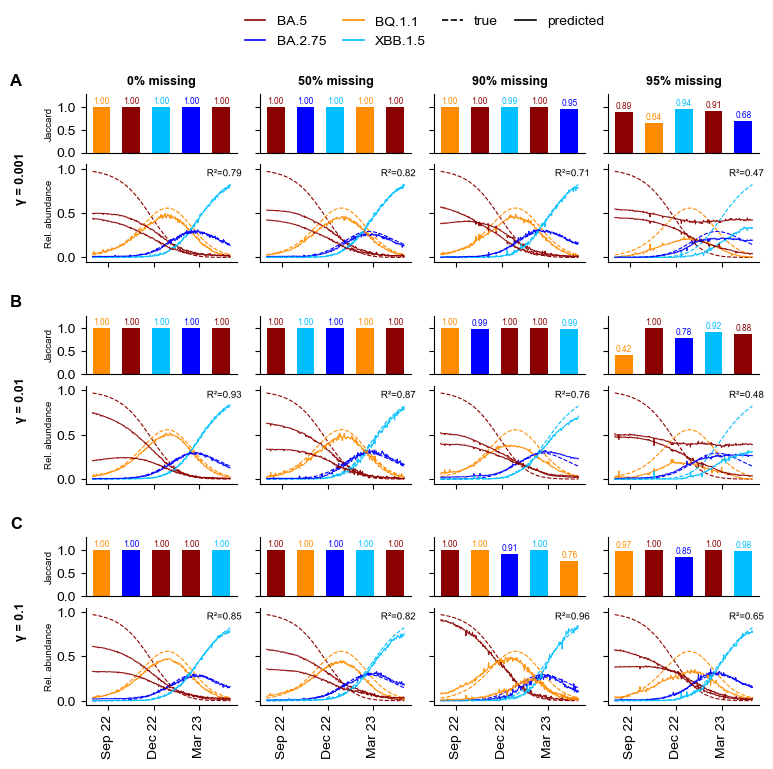

            tier  disp_level  missing_level  gamma  missing_frac       r2  n_variants_matched  n_variants_total  n_components  jaccard_all_components_mean  jaccard_all_components_min
 disp1_missing_1           1              1  0.001          0.00 0.792235                   4                 4             5                     1.000000                    1.000000
 disp1_missing_6           1              6  0.001          0.50 0.816212                   4                 4             5                     1.000000                    1.000000
disp1_missing_10           1             10  0.001          0.90 0.709466                   4                 4             5                     0.988475                    0.953488
disp1_missing_11           1             11  0.001          0.95 0.474547                   4                 4             5                     0.812833                    0.641026
 disp2_missing_1           2              1  0.010          0.00 0.925525            

In [31]:
def _r_squared(true_vals, pred_vals):
    true_vals = np.asarray(true_vals, dtype=float)
    pred_vals = np.asarray(pred_vals, dtype=float)
    ss_res = np.sum((true_vals - pred_vals) ** 2)
    ss_tot = np.sum((true_vals - true_vals.mean()) ** 2)
    return np.nan if ss_tot == 0 else 1 - ss_res / ss_tot


def _match_components_to_ground_truth_suboptimal(W_binary, W_covspectrum):
    """Every fitted component is assigned to whichever ground-truth variant
    it is most Jaccard-similar to (argmax) -- unconditionally. Multiple
    components can land on the same variant (many-to-one); there is no
    'unassigned' category."""
    all_muts = sorted(set(W_binary.index) | set(W_covspectrum.index))
    W_pred_final = W_binary.reindex(all_muts, fill_value=0)
    W_true_final = W_covspectrum.reindex(all_muts, fill_value=0)

    dist_matrix = cdist(W_pred_final.values.T, W_true_final.values.T, metric='jaccard')
    sim_matrix = 1 - dist_matrix

    sim_df = pd.DataFrame(sim_matrix, index=W_binary.columns, columns=W_covspectrum.columns)
    sim_df = sim_df.fillna(0.0)

    best_idx = sim_df.values.argmax(axis=1)
    best_labels = [sim_df.columns[i] for i in best_idx]

    counts = {}
    new_labels = []
    for lbl in best_labels:
        counts[lbl] = counts.get(lbl, 0) + 1
        new_labels.append(lbl if counts[lbl] == 1 else f"{lbl} ({counts[lbl]})")

    return sim_df, new_labels, best_labels


def _jaccard_per_variant(result, df, W_covspectrum, all_vars, binarize_threshold):
    """Runs the matching pipeline for one NMF result and returns
    (jaccard_per_variant, best_component_per_variant, label_to_k, H_norm,
     best_labels, jaccard_per_component).

    jaccard_per_variant / best_component_per_variant: per known ground-truth
    variant, the best-matching component's Jaccard score / label.

    best_labels / jaccard_per_component: per FITTED COMPONENT (in order
    Component_0..Component_{rank-1}), the matched ground-truth variant name
    and that component's own Jaccard similarity to it. Every component is
    matched to something -- see _match_components_to_ground_truth_suboptimal.
    """
    rank = result.W.shape[1]
    W_df = pd.DataFrame(result.W, index=list(df.index),
                         columns=[f'Component_{k}' for k in range(rank)])
    W_binary = (W_df >= binarize_threshold).astype(int)

    sim_df, new_labels, best_labels = _match_components_to_ground_truth_suboptimal(W_binary, W_covspectrum)
    jaccard_per_component = sim_df.max(axis=1).values  # one score per component, in component order
    sim_df.index = new_labels
    label_to_k = {label: k for k, label in enumerate(new_labels)}

    gt_to_pred_labels = {}
    for pred_label, gt_label in zip(new_labels, best_labels):
        gt_to_pred_labels.setdefault(gt_label, []).append(pred_label)

    jaccard_per_variant, best_component_per_variant = {}, {}
    for v in all_vars:
        candidates = gt_to_pred_labels.get(v, [])
        if not candidates:
            jaccard_per_variant[v] = np.nan
            best_component_per_variant[v] = None
            continue
        scores = {pl: sim_df.loc[pl, v] for pl in candidates}
        best_pl = max(scores, key=scores.get)
        jaccard_per_variant[v] = scores[best_pl]
        best_component_per_variant[v] = best_pl

    H_norm = result.H['sim'] / result.H['sim'].sum(axis=0, keepdims=True)
    return (jaccard_per_variant, best_component_per_variant, label_to_k, H_norm,
            best_labels, jaccard_per_component)


def evaluate_and_plot_grid_nature(nmf_results, datasets,
                                   W_covspectrum, abundance_matrix,
                                   tier_config=None,
                                   binarize_threshold=0.5,
                                   colors=None, fig_width_mm=183, cell_aspect=1.3):
    """Regularized-only version: one Jaccard-bar panel + one abundance panel
    per grid cell (no unregularized comparison)."""
    all_vars = list(W_covspectrum.columns)
    bar_colors = [colors.get(v, f'C{i}') if colors else f'C{i}' for i, v in enumerate(all_vars)]

    tier_grid = {}
    for tier in nmf_results:
        m = re.match(r'disp(\d+)_missing_(\d+)', tier)
        if not m:
            raise ValueError(f"Tier name '{tier}' doesn't match 'dispD_missing_M'.")
        tier_grid[(int(m.group(1)), int(m.group(2)))] = tier

    disp_levels = sorted({d for d, _ in tier_grid})
    missing_levels = sorted({mm for _, mm in tier_grid})
    n_rows, n_cols = len(disp_levels), len(missing_levels)

    row_headers = [f'disp {d}' for d in disp_levels]
    col_headers = [f'missing {mm}' for mm in missing_levels]
    gamma_by_disp, missfrac_by_col = {}, {}
    if tier_config is not None:
        cfg_by_name = {t['name']: t for t in tier_config}
        for (d, mm), name in tier_grid.items():
            cfg = cfg_by_name.get(name)
            if cfg is not None:
                gamma_by_disp[d] = cfg['gamma']
                missfrac_by_col[mm] = cfg['missing_frac']
        row_headers = [f'\u03b3 = {gamma_by_disp[d]:g}' for d in disp_levels]
        col_headers = [f'{missfrac_by_col[mm]*100:.0f}% missing' for mm in missing_levels]

    fig_w_in = fig_width_mm / 25.4
    fig_h_in = fig_w_in / n_cols * n_rows * cell_aspect
    fig = plt.figure(figsize=(fig_w_in, fig_h_in))
    outer = GridSpec(n_rows, n_cols, figure=fig,
                      left=0.06, right=0.995, top=0.92, bottom=0.05,
                      hspace=0.32, wspace=0.15)

    date_locator = mdates.MonthLocator(interval=3)
    date_formatter = mdates.DateFormatter('%b %y')
    r2_records = []
    bar_width = 0.6

    def _component_colors(best_labels):
        """One color per component, taken directly from the ground-truth
        palette -- the color of whichever variant it matched."""
        return [bar_colors[all_vars.index(v)] for v in best_labels]

    def _plot_abundance_panel(ax, dates, best_component_per_variant, label_to_k, H_norm,
                            component_colors):
        true_all, pred_all = [], []
        for i, v in enumerate(all_vars):
            ax.plot(dates, abundance_matrix[:, i], color=bar_colors[i],
                    linestyle='--', linewidth=0.8)

        rank = H_norm.shape[0]
        for k in range(rank):
            ax.plot(dates, H_norm[k], color=component_colors[k], linestyle='-', linewidth=0.8, alpha=0.9)

        n_matched = 0
        for i, v in enumerate(all_vars):
            best_pl = best_component_per_variant[v]
            true_all.append(abundance_matrix[:, i])
            if best_pl is not None:
                pred_all.append(H_norm[label_to_k[best_pl]])
                n_matched += 1
            else:
                # no component was assigned to this variant -- score it as a
                # predicted abundance of 0 everywhere, rather than dropping it
                pred_all.append(np.zeros_like(abundance_matrix[:, i]))

        ax.set_ylim(-0.05, 1.05)
        ax.set_yticks([0, 0.5, 1])
        ax.spines[['top', 'right']].set_visible(False)
        r2 = np.nan
        if true_all:
            r2 = _r_squared(np.concatenate(true_all), np.concatenate(pred_all))
            r2_text = ax.text(0.8, 0.95, f'R\u00b2={r2:.2f}', transform=ax.transAxes,
                            ha='left', va='top', fontsize=7, color='black', zorder=10)
            r2_text.set_path_effects([pe.withStroke(linewidth=2, foreground='white')])
        return r2, n_matched
    

    
    for r, disp_i in enumerate(disp_levels):
        for c, missing_j in enumerate(missing_levels):
            tier = tier_grid[(disp_i, missing_j)]
            df = datasets[tier]
            dates = pd.DatetimeIndex(df.columns)

            (jacc, best_component, label_to_k, H_norm,
             best_labels, jaccard_per_component) = _jaccard_per_variant(
                nmf_results[tier], df, W_covspectrum, all_vars, binarize_threshold)

            comp_colors = _component_colors(best_labels)

            inner = outer[r, c].subgridspec(2, 1, height_ratios=[0.6, 1.0], hspace=0.15)
            ax_bar = fig.add_subplot(inner[0])
            ax_ab = fig.add_subplot(inner[1])

            # ── Jaccard bars: one bar per fitted component ──
            rank = len(best_labels)
            xk = np.arange(rank)
            ax_bar.bar(xk, jaccard_per_component, width=bar_width, color=comp_colors)
            ax_bar.set_ylim(0, 1.28)
            ax_bar.set_yticks([0, 0.5, 1])
            ax_bar.set_xticks([])
            ax_bar.spines[['top', 'right']].set_visible(False)
            if c != 0:
                ax_bar.set_yticklabels([])
            for k in range(rank):
                val = jaccard_per_component[k]
                if not np.isnan(val):
                    ax_bar.text(xk[k], val + 0.03, f'{val:.2f}',
                                ha='center', va='bottom', fontsize=6, color=comp_colors[k])

            r2, n_matched = _plot_abundance_panel(
                ax_ab, dates, best_component, label_to_k, H_norm, comp_colors)

            ax_ab.xaxis.set_major_locator(date_locator)
            ax_ab.xaxis.set_major_formatter(date_formatter)
            ax_ab.tick_params(axis='x', rotation=90)
            if r != n_rows - 1:
                ax_ab.set_xticklabels([])
            if c != 0:
                ax_ab.set_yticklabels([])

            r2_records.append(dict(
                tier=tier, disp_level=disp_i, missing_level=missing_j,
                gamma=gamma_by_disp.get(disp_i), missing_frac=missfrac_by_col.get(missing_j),
                r2=r2, n_variants_matched=n_matched, n_variants_total=len(all_vars),
                n_components=rank,
                jaccard_all_components_mean=np.nanmean(jaccard_per_component),
                jaccard_all_components_min=np.nanmin(jaccard_per_component),
            ))

            if c == 0:
                ax_bar.set_ylabel('Jaccard', labelpad=2, fontsize=7)
                ax_ab.set_ylabel('Rel. abundance', labelpad=2, fontsize=7)
            if r == 0:
                ax_bar.set_title(col_headers[c], fontsize=9, pad=7, fontweight='bold')
        pos = outer[r, 0].get_position(fig)
        fig.text(-0.03, pos.y0 + pos.height / 2, row_headers[r],
                  rotation=90, va='center', ha='center', fontsize=9, fontweight='bold')
        fig.text(-0.045, pos.y1 + 0.008, chr(65 + r),
                  fontsize=12, fontweight='bold', ha='left', va='bottom')

    legend_handles = (
        [plt.Line2D([0], [0], color=bar_colors[i], lw=1.2, label=v) for i, v in enumerate(all_vars)]
        + [plt.Line2D([0], [0], color='black', lw=1.2, linestyle='--', label='true'),
           plt.Line2D([0], [0], color='black', lw=1.2, linestyle='-', label='predicted')]
    )
    fig.legend(handles=legend_handles, loc='upper center', ncol=4,
               frameon=False, bbox_to_anchor=(0.53, 1.05), handlelength=1.5, columnspacing=1.2)

    r2_df = pd.DataFrame(r2_records)
    return fig, r2_df


fig, r2_table = evaluate_and_plot_grid_nature(
    nmf_results_fitness_regularized, datasets,
    W_covspectrum=X, abundance_matrix=abundance_matrix,
    tier_config=QUALITY_TIERS, colors=colors)
fig.savefig('../results/simulated_data/fig_nmf_grid_simulation_2_fitness_5_variants.pdf', bbox_inches='tight')

plt.show()

print(r2_table.to_string(index=False))
#r2_table.to_csv('r2_estimates_per_tier.csv', index=False)

# Early detection of XBB.1.5 variant

In [52]:
# Before running the forecast, align the signature matrix
data = datasets_subset['disp1_missing_1']

# Keep only codons that are in both data AND W_covspectrum
common_codons = data.index.intersection(W_covspectrum.index)
print(f"Common codons: {len(common_codons)}")

data_aligned = data.loc[common_codons]
W_aligned = W_covspectrum.loc[common_codons]

print(f"data_aligned shape: {data_aligned.shape}")
print(f"W_aligned shape: {W_aligned.shape}")



Common codons: 116
data_aligned shape: (116, 274)
W_aligned shape: (116, 14)


## Emerging variant detection

Skipped (not in CV summary, no optimal parameters): ['disp1_missing_2', 'disp1_missing_3', 'disp1_missing_4', 'disp1_missing_5', 'disp1_missing_7', 'disp1_missing_8', 'disp1_missing_9']
Datasets: ['disp1_missing_1', 'disp1_missing_6', 'disp1_missing_10', 'disp1_missing_11']


disp1_missing_1: {'lambda_w': 8.0, 'lambda_h': 6.0, 'lambda_f': 10.0}
disp1_missing_1 | known: BA.5, BA.2.75, BQ.1.1 -> target: XBB.1.5
Dataset: 116 mutations x 274 timepoints

[1/33] T=45, forecasting to sample 51... ✓
[2/33] T=52, forecasting to sample 58... ✓
[3/33] T=59, forecasting to sample 65... ✓
[4/33] T=66, forecasting to sample 72... ✓
[5/33] T=73, forecasting to sample 79... ✓
[6/33] T=80, forecasting to sample 86... ✓
[7/33] T=87, forecasting to sample 93... ✓
[8/33] T=94, forecasting to sample 100... ✓
[9/33] T=101, forecasting to sample 107... ✓
[10/33] T=108, forecasting to sample 114... ✓
[11/33] T=115, forecasting to sample 121... ✓
[12/33] T=122, forecasting to sample 128... ✓
[13/33] T=129, for

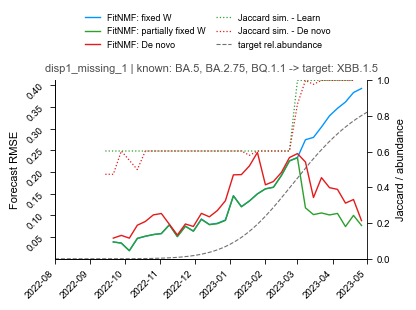


disp1_missing_1 | known: BA.5, BA.2.75, BQ.1.1 -> target: XBB.1.5:
  learn better than ignore in 75% of windows (mean RMSE improvement +0.0592)
  de novo better than ignore in 25% of windows

disp1_missing_6: {'lambda_w': 4.0, 'lambda_h': 10.0, 'lambda_f': 6.0}
disp1_missing_6 | known: BA.5, BA.2.75, BQ.1.1 -> target: XBB.1.5
Dataset: 116 mutations x 274 timepoints

[1/33] T=45, forecasting to sample 51... ✓
[2/33] T=52, forecasting to sample 58... ✓
[3/33] T=59, forecasting to sample 65... ✓
[4/33] T=66, forecasting to sample 72... ✓
[5/33] T=73, forecasting to sample 79... ✓
[6/33] T=80, forecasting to sample 86... ✓
[7/33] T=87, forecasting to sample 93... ✓
[8/33] T=94, forecasting to sample 100... ✓
[9/33] T=101, forecasting to sample 107... ✓
[10/33] T=108, forecasting to sample 114... ✓
[11/33] T=115, forecasting to sample 121... ✓
[12/33] T=122, forecasting to sample 128... ✓
[13/33] T=129, forecasting to sample 135... ✓
[14/33] T=136, forecasting to sample 142... ✓
[15/33] T=

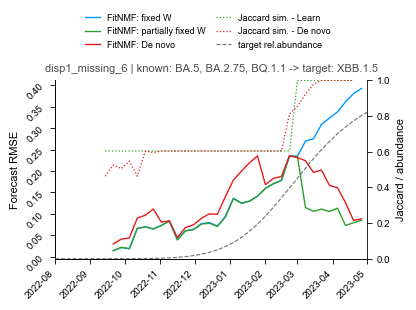


disp1_missing_6 | known: BA.5, BA.2.75, BQ.1.1 -> target: XBB.1.5:
  learn better than ignore in 81% of windows (mean RMSE improvement +0.0585)
  de novo better than ignore in 28% of windows

disp1_missing_10: {'lambda_w': 0.6, 'lambda_h': 1.0, 'lambda_f': 8.0}
disp1_missing_10 | known: BA.5, BA.2.75, BQ.1.1 -> target: XBB.1.5
Dataset: 116 mutations x 274 timepoints

[1/33] T=45, forecasting to sample 51... ✓
[2/33] T=52, forecasting to sample 58... ✓
[3/33] T=59, forecasting to sample 65... ✓
[4/33] T=66, forecasting to sample 72... ✓
[5/33] T=73, forecasting to sample 79... ✓
[6/33] T=80, forecasting to sample 86... ✓
[7/33] T=87, forecasting to sample 93... ✓
[8/33] T=94, forecasting to sample 100... ✓
[9/33] T=101, forecasting to sample 107... ✓
[10/33] T=108, forecasting to sample 114... ✓
[11/33] T=115, forecasting to sample 121... ✓
[12/33] T=122, forecasting to sample 128... ✓
[13/33] T=129, forecasting to sample 135... ✓
[14/33] T=136, forecasting to sample 142... ✓
[15/33] T

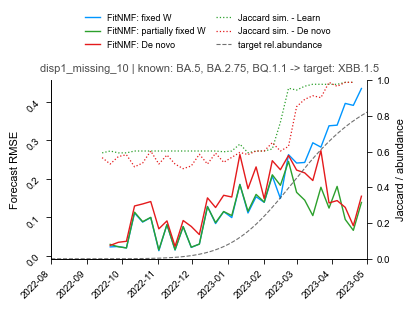


disp1_missing_10 | known: BA.5, BA.2.75, BQ.1.1 -> target: XBB.1.5:
  learn better than ignore in 47% of windows (mean RMSE improvement +0.0534)
  de novo better than ignore in 31% of windows

disp1_missing_11: {'lambda_w': 0.1, 'lambda_h': 3.0, 'lambda_f': 20.0}
disp1_missing_11 | known: BA.5, BA.2.75, BQ.1.1 -> target: XBB.1.5
Dataset: 116 mutations x 274 timepoints

[1/33] T=45, forecasting to sample 51... ✓
[2/33] T=52, forecasting to sample 58... ✓
[3/33] T=59, forecasting to sample 65... ✓
[4/33] T=66, forecasting to sample 72... ✓
[5/33] T=73, forecasting to sample 79... ✓
[6/33] T=80, forecasting to sample 86... ✓
[7/33] T=87, forecasting to sample 93... ✓
[8/33] T=94, forecasting to sample 100... ✓
[9/33] T=101, forecasting to sample 107... ✓
[10/33] T=108, forecasting to sample 114... ✓
[11/33] T=115, forecasting to sample 121... ✓
[12/33] T=122, forecasting to sample 128... ✓
[13/33] T=129, forecasting to sample 135... ✓
[14/33] T=136, forecasting to sample 142... ✓
[15/33]

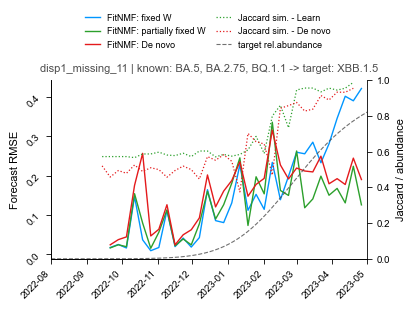


disp1_missing_11 | known: BA.5, BA.2.75, BQ.1.1 -> target: XBB.1.5:
  learn better than ignore in 44% of windows (mean RMSE improvement +0.0306)
  de novo better than ignore in 28% of windows

                   n_windows  learn_better_than_ignore  denovo_better_than_ignore  mean_rmse_ignore  mean_rmse_learn  mean_rmse_denovo  max_jaccard_learn  max_jaccard_denovo  lambda_w  lambda_h  lambda_f
dataset                                                                                                                                                                                                   
disp1_missing_1          32                    0.7500                     0.2500            0.1598           0.1006            0.1360             1.0000              1.0000       8.0       6.0      10.0
disp1_missing_6          32                    0.8125                     0.2812            0.1581           0.0996            0.1338             1.0000              1.0000       4.0      10.0    

In [36]:
# ── Config ───────────────────────────────────────────────────────────────────
KNOWN_VARIANTS    = ['BA.5', 'BA.2.75', 'BQ.1.1']
TARGET_VARIANT    = 'XBB.1.5'
DENOVO_RANK       = 4   # len(KNOWN_VARIANTS) + 1

MIN_WINDOW        = 45
TRAIN_STEP        = 7
FORECAST_HORIZON  = 7
# Fallback values, used only if no params are passed to main()
LAMBDA_F          = 10.0
LAMBDA_H          = 6
LAMBDA_W          = 8
BANDWIDTH         = 10
N_RUN             = 10
LAMBDA_MASK       = 1000   # only used for the partially-masked ("learn") fit

DATASET_PREFIX    = 'disp1_missing_'
# Label of each dataset in the CV summary (column 'sim', or 'location' in the raw CSV),
# e.g. 'disp1_missing_6_omicron_replicator'
SIM_NAME          = lambda ds: f'{ds}_omicron_replicator'

COL_IGNORE  = '#0096FF'   # bright/"shiny" blue
COL_LEARN   = '#2CA02C'   # green
COL_DENOVO  = '#E41A1C'   # red
COL_TRUTH   = '#4D4D4D'   # neutral grey

mpl.rcParams.update({
    'font.family':       'sans-serif',
    'font.sans-serif':   ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size':          8,
    'axes.titlesize':     9,
    'axes.labelsize':     8,
    'xtick.labelsize':    7,
    'ytick.labelsize':    7,
    'legend.fontsize':    7,
    'axes.linewidth':     0.6,
    'xtick.major.width':  0.6,
    'ytick.major.width':  0.6,
    'lines.linewidth':    1.0,
    'savefig.dpi':        300,
    'pdf.fonttype':       42,
    'ps.fonttype':        42,
})


# ── Hyperparameters from CV ──────────────────────────────────────────────────

def best_params_from_cv(summ, sim_name, rank=DENOVO_RANK):
    """Minimum mean CV error at the given rank, restricted to lambda_f > 0.
    Expects columns: sim (or location), n_variants, lambda_w, lambda_h, lambda_f, mean_error."""
    col = 'sim' if 'sim' in summ.columns else 'location'
    s = summ[(summ[col] == sim_name) & (summ.n_variants == rank) & (summ.lambda_f > 0)]
    if s.empty:
        raise ValueError(f"no CV rows for {col}={sim_name!r}, rank={rank}; "
                         f"available: {sorted(summ[col].unique())[:20]}")
    b = s.loc[s.mean_error.idxmin()]
    return dict(lambda_w=float(b.lambda_w), lambda_h=float(b.lambda_h),
                lambda_f=float(b.lambda_f))


# ── Model fits ───────────────────────────────────────────────────────────────

def fit_model(data_window, W_aligned, known_variants, add_free_slot,
              lambda_mask=LAMBDA_MASK, **nmf_kwargs):
    """
    Fit f, b, W with the known variants soft-pinned (regularized toward Q,
    not hard-clamped). If add_free_slot, appends one unconstrained
    component (rank = n_known + 1); otherwise rank = n_known exactly
    (fully closed system).

    Masking mode depends on which case this is:
      - add_free_slot=False ("ignore"): EVERY column is pinned (fully
        masked) -- use masking_option=2, the original script's mode for a
        fully-closed, all-known system.
      - add_free_slot=True ("learn"): only n_known of the rank columns are
        pinned, one is left free (partial masking) -- use masking_option=1
        with lambda_mask, which supports a softer, partially-masked fit.
    """
    n_known = len(known_variants)
    rank = n_known + (1 if add_free_slot else 0)

    Q_known = W_aligned[known_variants].values.astype(float)
    Q_padded = np.zeros((Q_known.shape[0], rank))
    Q_mask_padded = np.zeros((Q_known.shape[0], rank))
    Q_padded[:, :n_known] = Q_known
    Q_mask_padded[:, :n_known] = 1.0

    # NOTE: dict-wrapped -- this NMF entry point expects {location: df}
    data_dict = {'location': data_window}

    if add_free_slot:
        # Partial masking (3 pinned + 1 free) -- soft mode 1
        result = joint_soft_dynamics_nmf(
            data_dict, rank=rank, masking_option=1, lambda_mask=lambda_mask,
            Q=Q_padded, Q_mask=Q_mask_padded,  **nmf_kwargs)
    else:
        # Fully masked (all columns pinned) -- mode 2, matches original script
        result = joint_soft_dynamics_nmf(
            data_dict, rank=rank, masking_option=2,
            Q=Q_padded, Q_mask=Q_mask_padded, **nmf_kwargs)
    return result, rank


def fit_model_denovo(data_window, rank, **nmf_kwargs):
    """Fully unconstrained NMF -- no known-variant pinning at all."""
    data_dict = {'location': data_window}
    result = joint_soft_dynamics_nmf(
        data_dict, rank=rank, masking_option=0, **nmf_kwargs)
    return result


# ── Jaccard scores ───────────────────────────────────────────────────────────

def free_column_jaccard(result, W_aligned, target_variant, n_known):
    """Jaccard between the (binarized) free column and the target's true
    signature. Assumes column index n_known is the single unpinned column."""
    if result.W.shape[1] <= n_known:
        return np.nan
    free_col_idx = n_known
    W_free = binarize_signature_matrix(result.W[:, [free_col_idx]])
    W_t = binarize_signature_matrix(W_aligned[[target_variant]].values)
    dist = cdist(W_free.T, W_t.T, metric='jaccard')
    return float(1 - dist[0, 0])


def denovo_target_jaccard_hungarian(result, W_aligned, known_variants, target_variant):
    """
    Jaccard between the target's true signature and its Hungarian-assigned
    predicted column, for a fully unconstrained ("de novo") fit.

    Run the Hungarian algorithm once to get the single globally-optimal
    one-to-one pairing between all predicted columns and all ground-truth
    variants, then read off whichever predicted column got assigned to
    the target.
    """
    gt_variants = list(known_variants) + [target_variant]
    target_idx = len(known_variants)   # target is appended last

    W_pred = binarize_signature_matrix(result.W)
    W_gt = binarize_signature_matrix(W_aligned[gt_variants].values)

    dist = cdist(W_pred.T, W_gt.T, metric='jaccard')
    sim = 1 - dist   # (rank, rank) -- square, since rank == n_known + 1 == len(gt_variants)

    row_ind, col_ind = linear_sum_assignment(-sim)
    assigned = dict(zip(col_ind, sim[row_ind, col_ind]))
    return float(assigned.get(target_idx, np.nan))


# ── Expanding-window forecast comparison ─────────────────────────────────────

def run_comparison(data, W_aligned, known_variants, target_variant,
                   min_window=MIN_WINDOW, train_step=TRAIN_STEP,
                   horizon=FORECAST_HORIZON, denovo_rank=None,
                   verbose=True, **nmf_kwargs):
    try:
        dates = pd.to_datetime(data.columns, format='%Y_%m_%d')
    except ValueError:
        dates = pd.to_datetime(data.columns)
    n_days = len(dates)
    n_known = len(known_variants)
    rank_denovo = denovo_rank if denovo_rank is not None else n_known + 1

    if n_known < 2:
        print(f"    note: only {n_known} known lineage(s) -- 'ignore' would be a rank-1 "
              f"model (a single component is forced to proportion 1.0 for all time, so "
              f"there's no growth-curve parameter to fit and the optimizer errors on an "
              f"empty gradient). Skipping 'ignore' for this step; 'learn'/'de novo' are "
              f"unaffected since they're rank >= 2.")

    records = []
    window_range = list(range(min_window, n_days, train_step))

    for wi, T in enumerate(window_range, start=1):
        train_window = data.iloc[:, :T]

        # Calendar-day-based forecast horizon
        train_end_date = dates[T - 1]
        forecast_target_date = train_end_date + pd.Timedelta(days=horizon)

        # Find closest sample >= forecast_target_date using searchsorted
        valid_idx = np.searchsorted(dates[T:].values, forecast_target_date)
        if valid_idx >= len(dates[T:]):
            break

        forecast_idx = T + valid_idx
        if forecast_idx >= len(dates):
            break

        actual = data.iloc[:, T:forecast_idx + 1].values
        M = (~np.isnan(actual)).astype(float)

        n_forecast_samples = forecast_idx - T + 1
        t_future = np.arange(T, T + n_forecast_samples, dtype=float)

        if verbose:
            print(f"[{wi}/{len(window_range)}] T={T}, forecasting to sample {forecast_idx}...",
                  end=' ', flush=True)

        def score(result):
            # result.b comes back keyed by location (dict) since we wrap
            # data as {'location': ...} above -- unwrap before compute_p.
            b_arr = result.b['location'] if isinstance(result.b, dict) else result.b
            H_forecast = compute_p(result.f, b_arr, t_future)
            # W: binarize before using it as a signature matrix to project
            # forecasted abundances.
            A_forecast = binarize_signature_matrix(result.W) @ H_forecast
            if M.sum() == 0:
                return np.nan
            diff = (A_forecast - np.where(np.isnan(actual), 0.0, actual)) * M
            return float(np.sqrt(np.sum(diff ** 2) / M.sum()))

        try:
            if n_known >= 2:
                result_ignore, _ = fit_model(train_window, W_aligned, known_variants,
                                             add_free_slot=False, **nmf_kwargs)
                rmse_ignore = score(result_ignore)
            else:
                rmse_ignore = np.nan

            result_learn, _ = fit_model(train_window, W_aligned, known_variants,
                                        add_free_slot=True, **nmf_kwargs)
            result_denovo = fit_model_denovo(train_window, rank=rank_denovo, **nmf_kwargs)

            rmse_learn = score(result_learn)
            rmse_denovo = score(result_denovo)
            jaccard = free_column_jaccard(result_learn, W_aligned, target_variant, n_known)
            jaccard_denovo = denovo_target_jaccard_hungarian(
                result_denovo, W_aligned, known_variants, target_variant)
        except Exception as e:
            print(f"⚠️  fit failed: {str(e)[:100]}")
            rmse_ignore = rmse_learn = rmse_denovo = np.nan
            jaccard = jaccard_denovo = np.nan

        records.append({
            'train_end_date':    dates[T - 1],
            'forecast_end_date': dates[forecast_idx],
            'rmse_ignore': rmse_ignore,
            'rmse_learn':  rmse_learn,
            'rmse_denovo': rmse_denovo,
            'rmse_improvement': (rmse_ignore - rmse_learn
                                 if np.isfinite(rmse_ignore) and np.isfinite(rmse_learn) else np.nan),
            'learn_better': (rmse_learn < rmse_ignore
                             if np.isfinite(rmse_ignore) and np.isfinite(rmse_learn) else None),
            'denovo_better_than_ignore': (rmse_denovo < rmse_ignore
                                          if np.isfinite(rmse_ignore) and np.isfinite(rmse_denovo) else None),
            'free_col_jaccard_to_target': jaccard,
            'denovo_best_jaccard_to_target': jaccard_denovo,
        })

        if verbose:
            print("✓")

    return records


# ── Figure ───────────────────────────────────────────────────────────────────

def make_figure(records, step_label, target_variant, true_abundance,
                step_window, out_stem='forecast_xbb1p5_simulation'):
    """
    Single-panel figure: forecast RMSE (ignore/learn/de novo) plus
    free-column Jaccard-to-target and (optionally) the true target
    abundance curve on a twin axis.

    true_abundance: pd.Series indexed by date, or None.
    """

    fig, ax = plt.subplots(figsize=(4.2, 2.6))
    fd = [r['train_end_date'] for r in records]

    fe = [r['forecast_end_date'] for r in records]                    # new: used by the RMSE lines

    h1, = ax.plot(fe, [r['rmse_ignore'] for r in records],
                color=COL_IGNORE, label='FitNMF: fixed W')
    h2, = ax.plot(fe, [r['rmse_learn'] for r in records],
                  color=COL_LEARN, label='FitNMF: partially fixed W')
    h5, = ax.plot(fe, [r['rmse_denovo'] for r in records], color=COL_DENOVO, label='FitNMF: De novo')



    ax.set_ylabel('Forecast RMSE')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(direction='out', labelrotation=45)
    for label in ax.get_xticklabels():
        label.set_ha('right')

    ax2 = ax.twinx()
    h3, = ax2.plot(fd, [r['free_col_jaccard_to_target'] for r in records],
                   color=COL_LEARN, linestyle=':', linewidth=0.9,
                   label='Jaccard sim. - Learn')
    h6, = ax2.plot(fd, [r['denovo_best_jaccard_to_target'] for r in records],
                   color=COL_DENOVO, linestyle=':', linewidth=0.9,
                   label='Jaccard sim. - De novo')
    handles = [h1, h2, h5, h3, h6]
    if true_abundance is not None:
        h4, = ax2.plot(true_abundance.index, true_abundance.values,
                       color=COL_TRUTH, linestyle='--', linewidth=0.8,
                       alpha=0.8, label='target rel.abundance')
        handles.append(h4)
    ax2.set_ylim(0, 1)
    ax2.set_ylabel('Jaccard / abundance')
    ax2.spines['top'].set_visible(False)
    ax2.tick_params(direction='out')

    if step_window is not None:
        window_start, window_end = step_window
        for a in (ax, ax2):
            a.set_autoscalex_on(False)
            a.set_xlim(window_start, window_end)

    ax.set_title(step_label, fontsize=8, color='0.3')

    fig.legend(handles, [h.get_label() for h in handles], loc='upper center',
               bbox_to_anchor=(0.5, 1.18), ncol=2, frameon=False,
               handlelength=1.6, columnspacing=1.2, fontsize=6.5)

    plt.tight_layout()
    fig.savefig(f'{out_stem}.pdf', bbox_inches='tight')
    fig.savefig(f'{out_stem}.png', bbox_inches='tight')
    plt.show()
    plt.close(fig)


# ── One dataset ──────────────────────────────────────────────────────────────

def main(data, W_covspectrum, known_variants=KNOWN_VARIANTS,
         target_variant=TARGET_VARIANT, denovo_rank=DENOVO_RANK,
         true_abundance=None, out_stem='forecast_xbb1p5_simulation',
         params=None, tag=''):
    """
    Args:
        data: (n_codons, n_timepoints) DataFrame for ONE simulated dataset,
              e.g. datasets['disp1_missing_6'].
        W_covspectrum: (n_codons, n_variants) ground-truth signature matrix
              -- must include columns for known_variants + target_variant.
        true_abundance: optional pd.Series (date-indexed) with the true
              target relative-abundance trajectory to overlay on the figure.
        params: dict(lambda_w, lambda_h, lambda_f); missing keys fall back to
              the LAMBDA_* constants.
        tag: prefix for the figure title (e.g. the dataset name).
    """
    data_sorted = data.sort_index(axis=1)
    W_aligned_full = W_covspectrum.reindex(data_sorted.index, fill_value=0)

    needed = known_variants + [target_variant]
    missing = [v for v in needed if v not in W_aligned_full.columns]
    if missing:
        raise KeyError(
            f"W_covspectrum is missing signature definitions for {missing} -- "
            f"fetch/add these lineages before running this script.")

    # Align mutations: data and W_covspectrum must have the same codon index
    common_codons = data_sorted.index.intersection(W_aligned_full.index)
    if len(common_codons) < data_sorted.shape[0] or len(common_codons) < W_aligned_full.shape[0]:
        print(f"Aligning mutations: data had {data_sorted.shape[0]}, W_covspectrum had "
              f"{W_aligned_full.shape[0]}, {len(common_codons)} in common.")
    data_sorted = data_sorted.loc[common_codons]
    W_aligned_full = W_aligned_full.loc[common_codons]

    p = params or {}
    nmf_kwargs = dict(rel_tol=1e-4,
                      lambda_w=p.get('lambda_w', LAMBDA_W),
                      lambda_h=p.get('lambda_h', LAMBDA_H),
                      lambda_f=p.get('lambda_f', LAMBDA_F),
                      bandwidth=BANDWIDTH, n_run=N_RUN,
                      random_state=42, n_jobs=-1)

    step_label = f"{tag}known: {', '.join(known_variants)} -> target: {target_variant}"
    print(f"{step_label}")
    print(f"Dataset: {data_sorted.shape[0]} mutations x {data_sorted.shape[1]} timepoints\n")

    try:
        all_dates = pd.to_datetime(data_sorted.columns, format='%Y_%m_%d')
    except ValueError:
        all_dates = pd.to_datetime(data_sorted.columns)
    step_window = (all_dates.min(), all_dates.max())

    records = run_comparison(
        data_sorted, W_aligned_full, known_variants, target_variant,
        denovo_rank=denovo_rank, verbose=True, **nmf_kwargs)

    make_figure(records, step_label, target_variant, true_abundance, step_window,
                out_stem=out_stem)

    # ── Summary ──────────────────────────────────────────────────────────────
    summary = pd.DataFrame(records)
    summary.insert(0, 'target', target_variant)
    summary.to_csv(f'{out_stem}.csv', index=False)

    sub = summary.dropna(subset=['learn_better'])
    if len(sub) == 0:
        print(f"\n{step_label}: no comparable windows "
              f"({len(summary)} windows; NaN RMSE: ignore={summary['rmse_ignore'].isna().sum()}, "
              f"learn={summary['rmse_learn'].isna().sum()}, denovo={summary['rmse_denovo'].isna().sum()}) "
              f"-- see the 'fit failed' messages above")
    else:
        win_rate = sub['learn_better'].mean()
        mean_improve = sub['rmse_improvement'].mean()
        denovo_sub = sub.dropna(subset=['denovo_better_than_ignore'])
        denovo_win_rate = denovo_sub['denovo_better_than_ignore'].mean() if len(denovo_sub) else float('nan')
        print(f"\n{step_label}:")
        print(f"  learn better than ignore in {win_rate:.0%} of windows "
              f"(mean RMSE improvement {mean_improve:+.4f})")
        print(f"  de novo better than ignore in {denovo_win_rate:.0%} of windows")

    return summary


# ── All disp1 datasets ───────────────────────────────────────────────────────

def run_all_disp1(datasets, summ, W_covspectrum, true_abundance=None,
                  prefix=DATASET_PREFIX, sim_name=SIM_NAME, out_prefix='forecast_xbb1p5'):
    """Run main() on every dataset whose key starts with `prefix` (all missing
    fractions), each with its own CV-optimal hyperparameters."""
    all_names = sorted([k for k in datasets if k.startswith(prefix)],
                       key=lambda k: int(k.split('_')[-1]))
    if not all_names:
        raise KeyError(f"no datasets with keys starting with {prefix!r}; "
                       f"available: {list(datasets)[:20]}")
    # Only datasets that were part of the CV have optimal parameters
    col = 'sim' if 'sim' in summ.columns else 'location'
    cv_labels = set(summ[col].unique())
    names = [k for k in all_names if sim_name(k) in cv_labels]
    skipped = [k for k in all_names if k not in names]
    if skipped:
        print(f"Skipped (not in CV summary, no optimal parameters): {skipped}")
    if not names:
        raise KeyError(f"none of {all_names} found in the CV summary as "
                       f"{sim_name(all_names[0])!r}-style labels")
    print(f"Datasets: {names}\n")

    all_summ, chosen = [], {}
    for name in names:
        params = best_params_from_cv(summ, sim_name(name))
        chosen[name] = params
        print(f"\n{'=' * 70}\n{name}: {params}\n{'=' * 70}")
        s = main(datasets[name], W_covspectrum, true_abundance=true_abundance,
                 params=params, tag=f"{name} | ", out_stem=f'{out_prefix}_{name}')
        s.insert(0, 'dataset', name)
        all_summ.append(s)

    all_df = pd.concat(all_summ, ignore_index=True)
    params_df = pd.DataFrame(chosen).T
    params_df.index.name = 'dataset'

    # Per-dataset summary: win rates and mean RMSE
    rows = []
    for name, g in all_df.groupby('dataset', sort=False):
        comp = g.dropna(subset=['learn_better'])
        rows.append({
            'dataset': name,
            'n_windows': len(g),
            'learn_better_than_ignore': comp['learn_better'].astype(float).mean() if len(comp) else np.nan,
            'denovo_better_than_ignore': comp['denovo_better_than_ignore'].astype(float).mean() if len(comp) else np.nan,
            'mean_rmse_ignore': g['rmse_ignore'].mean(),
            'mean_rmse_learn': g['rmse_learn'].mean(),
            'mean_rmse_denovo': g['rmse_denovo'].mean(),
            'max_jaccard_learn': g['free_col_jaccard_to_target'].max(),
            'max_jaccard_denovo': g['denovo_best_jaccard_to_target'].max(),
        })
    summary_df = pd.DataFrame(rows).set_index('dataset').join(params_df)

    all_df.to_csv(f'{out_prefix}_disp1_all.csv', index=False)
    params_df.to_csv(f'../results/simulated_data/{out_prefix}_disp1_params.csv')
    summary_df.to_csv(f'../results/simulated_data/{out_prefix}_disp1_summary.csv')
    print('\n', summary_df.round(4).to_string())
    return all_df, summary_df


if __name__ == '__main__':
    # Expects, from your notebook/session: datasets, summ (CV summary), W_covspectrum,
    # all_vars, P_sim, date_range
    xbb_idx = all_vars.index('XBB.1.5')
    true_abundance = pd.Series(P_sim[:, xbb_idx], index=date_range, name='XBB.1.5')


    all_df, summary_df = run_all_disp1(datasets, simulated_data_cv, W_covspectrum,
                                       true_abundance=true_abundance)